# 11. Sarampo no Brasil (1990–2026): Small Multiples Geográficos em Perspectiva Social, Política e Demográfica

**Disciplina:** Análise Visual de Dados — Mestrado UNESP  
**Técnica Central:** *Small Multiples* com Mapas Coropléticos Geográficos, Cartogramas Hexagonais e Escalas Compartilhadas (Tufte, Munzner e Ware)

---

## 1. O Salto Analítico dos Novos Dados (`data/gold/`)

Com a consolidação da camada `data/gold/` completa (versão `2026-11-08`), este notebook dá um passo além da análise puramente descritiva de doses do [Notebook 10](10-small-multiples-geograficos.ipynb), integrando **cinco dimensões complementares**:

1. **Vigilância Epidemiológica Histórica (`data/gold/sinan/`):** Série consolidada de **casos confirmados e óbitos (1990–2026)** e **255.858 notificações individuais (2007–2026)** com raça/cor, faixa etária, hospitalização e histórico vacinal.
2. **Cobertura Vacinal Real (`data/gold/demografia/`):** Cobertura oficial de 1ª dose (**D1**) e 2ª dose (**D2**) em crianças de 1 ano (**1994–2026**), usando como denominador os **nascidos vivos do SINASC** — e não mais a população total fixa.
3. **Dimensão Política e Governança Federativa:** Evolução da cobertura nos **4 ciclos político-sanitários (2013–2026)**, cruzada com a **homogeneidade municipal (meta de 95%)** e com o **alinhamento eleitoral estadual (TSE, 2º turno 2022)**.
4. **Dimensão Social, Racial e de Acesso ao SUS:** Cruzamento entre **rendimento real domiciliar per capita (IBGE SIDRA, PNAD Contínua Anual 2025)**, dependência do SUS vs. rede privada (`gold_estabelecimento`), invisibilidade do quesito raça/cor (`gold_perfil`) e desigualdade racial/etária na hospitalização por sarampo (SINAN).
5. **Dimensão Demográfica (`SINASC` + `IBGE/POPSVS`):** 30 anos de **transição demográfica (1995–2025)** e variação recente de nascidos vivos (**2015–2024**), expondo o encolhimento da base infantil no Sul/Sudeste versus o choque migratório na fronteira Norte.

---

## 2. Escolhas de Design Visual (Fundamentação em Análise Visual de Dados)

| Matriz | Dimensão | Técnica Cartográfica | Decisão de Cor / Escala |
|---|---|---|---|
| **Matriz 1** | **Ondas Epidêmicas (1997–2026)** | Grade 2×4 coropléticos (incidência / 100 mil hab.) | **Escala logarítmica discreta (`YlOrRd`)** — evita que um surto extremo (AM 218/100k) apague surtos menores (CE 2014, TO 2025, SP 2026) |
| **Matriz 2** | **Ciclos Político-Sanitários (2013–2026)** | Grade 2×4 coropléticos (D1 e D2 em 4 ciclos) | **Divergente (`RdYlBu`) centrada na meta oficial de 95% do PNI** — leitura imediata de déficit (vermelho) vs. meta cumprida (azul) |
| **Matriz 3** | **Política, Renda e Recuperação (2021→2026)** | Grade 2×3 (Mapas + Cartograma Hexagonal) + Dispersão | **Cruzamento visual** TSE 2022 × Renda IBGE 2025 × Recuperação D1/D2 × Homogeneidade Municipal |
| **Matriz 4** | **Desigualdade Social, Racial e SUS** | Grade 2×2 coropléticos + Barras de Gravidade | Contrasta rede privada, apagão racial, fronteira indígena e **taxa de não-vacinados / hospitalização** |
| **Matriz 5** | **Transição Demográfica (1995–2025)** | Grade 2×3 (3 décadas + SINASC + Hexagonal) | Escala sequencial compartilhada (`YlGnBu`) para `% < 5 anos` + divergente (`RdBu`) para variação de nascidos vivos |

## 1. Setup, Infraestrutura Cartográfica e Carga dos Dados

In [ ]:
import json
import os
import tempfile
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", tempfile.gettempdir())

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.collections import PolyCollection
from matplotlib.patches import RegularPolygon
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# Paleta editorial e estilo padronizado
# ------------------------------------------------------------------------------
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
RED = "#c2272d"
PURPLE = "#6a3d9a"
GOLD_COL = "#d99b00"
TEXT_PRIMARY, TEXT_SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEM_DADO = "#d9d8d0"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "text.color": TEXT_PRIMARY,
    "font.size": 10,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def resolver_caminho(caminho_rel: str) -> Path:
    for base in [Path("."), Path(".."), Path("../..")]:
        cand = base / caminho_rel
        if cand.exists():
            return cand
    return Path(caminho_rel)

GOLD = resolver_caminho("data/gold")
REF = resolver_caminho("data/referencia")
GEO = GOLD / "ibge" if (GOLD / "ibge" / "uf.json").exists() else resolver_caminho("data/bronze/ibge")

# ------------------------------------------------------------------------------
# Malha leve GeoJSON do IBGE (sem dependência de geopandas)
# ------------------------------------------------------------------------------
def ler_geojson(caminho: Path, chave_len: int):
    features = json.loads(Path(caminho).read_text(encoding="utf-8"))["features"]
    codigos, verts, dono = [], [], []
    for i, f in enumerate(features):
        codigos.append(f["properties"]["codarea"][:chave_len])
        g = f["geometry"]
        aneis = [g["coordinates"][0]] if g["type"] == "Polygon" else [p[0] for p in g["coordinates"]]
        for anel in aneis:
            verts.append(np.asarray(anel))
            dono.append(i)
    return codigos, verts, np.array(dono)

def centroide(anel):
    x, y = anel[:, 0], anel[:, 1]
    a = x[:-1] * y[1:] - x[1:] * y[:-1]
    area = a.sum() / 2
    if abs(area) < 1e-12:
        return anel.mean(axis=0)
    return np.array([((x[:-1] + x[1:]) * a).sum(), ((y[:-1] + y[1:]) * a).sum()]) / (6 * area)

uf_meta = pd.DataFrame(json.loads((GEO / "uf_meta.json").read_text(encoding="utf-8")))
ID_STR_PARA_SIGLA = dict(zip(uf_meta["id"].astype(str), uf_meta["sigla"]))
ID_INT_PARA_SIGLA = dict(zip(uf_meta["id"].astype(int), uf_meta["sigla"]))
REGIAO = dict(zip(uf_meta["sigla"], uf_meta["regiao"].map(lambda r: r["nome"])))

cod_uf, verts_uf, dono_uf = ler_geojson(GEO / "uf.json", 2)
sigla_uf = [ID_STR_PARA_SIGLA[c] for c in cod_uf]
SIGLAS = sorted(sigla_uf)
cent_uf = {s: centroide(max([v for v, d in zip(verts_uf, dono_uf) if d == i], key=len))
           for i, s in enumerate(sigla_uf)}

LIM_X, LIM_Y = (-74.2, -33.5), (-34.2, 5.6)
ASPECTO = 1 / np.cos(np.radians(-15))

def base_mapa(ax):
    ax.set_xlim(*LIM_X)
    ax.set_ylim(*LIM_Y)
    ax.set_aspect(ASPECTO)
    ax.axis("off")

def coropletico(ax, valores, norm=None, cmap="Blues", bins=None, extremos="neither",
                titulo=None, subtitulo=None, rotulo=None, colorbar=True, fmt="{:,.0f}", cbar_kw=None,
                titulo_fs=10.5):
    v = np.array([valores.get(c, np.nan) for c in sigla_uf], dtype=float)[dono_uf]
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad(SEM_DADO)
    if norm is None:
        if bins is not None:
            norm = mcolors.BoundaryNorm(bins, cm.N, extend=extremos)
        else:
            valid = v[~np.isnan(v)]
            norm = mcolors.Normalize(vmin=valid.min() if len(valid) else 0,
                                     vmax=valid.max() if len(valid) else 1)
    pc = PolyCollection(verts_uf, array=np.ma.masked_invalid(v), cmap=cm, norm=norm,
                        edgecolors="white", linewidths=0.55, zorder=1)
    ax.add_collection(pc)
    base_mapa(ax)
    if titulo:
        t = f"{titulo}\n{subtitulo}" if subtitulo else titulo
        ax.set_title(t, loc="left", fontweight="bold", fontsize=titulo_fs, pad=4)
    if colorbar:
        kw = dict(shrink=0.55, pad=0.01, aspect=22)
        kw.update(cbar_kw or {})
        cb = plt.colorbar(pc, ax=ax, **kw)
        cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: fmt.format(x).replace(",", ".")))
        if rotulo:
            cb.set_label(rotulo, fontsize=9)
    return pc

HEX_COORDS = {
    "RR": (2, 7), "AP": (6, 7),
    "AM": (1, 6), "PA": (4, 6), "TO": (5, 5), "RO": (2, 5), "AC": (0, 5),
    "MA": (6, 6), "PI": (6, 5), "CE": (7, 6), "RN": (8, 6), "PB": (8, 5),
    "PE": (8, 4), "AL": (8, 3), "SE": (7, 3), "BA": (6, 4),
    "MT": (3, 5), "GO": (4, 4), "DF": (5, 4), "MS": (3, 3),
    "MG": (5, 3), "ES": (6, 3), "RJ": (5, 2), "SP": (4, 2),
    "PR": (4, 1), "SC": (4, 0), "RS": (4, -1),
}

def cartograma_hexagonal(ax, valores, norm=None, cmap="Blues", titulo=None, fmt="{:.0f}",
                         tamanho_sigla=7.5, tamanho_val=6.2):
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad(SEM_DADO)
    vs = pd.Series(valores).dropna()
    if norm is None:
        norm = mcolors.Normalize(vmin=vs.min(), vmax=vs.max())
    for uf, (x, y) in HEX_COORDS.items():
        val = valores.get(uf, np.nan)
        if np.isnan(val):
            fc, cor_txt = SEM_DADO, TEXT_SECONDARY
        else:
            fc = cm(norm(val))
            lum = 0.299 * fc[0] + 0.587 * fc[1] + 0.114 * fc[2]
            cor_txt = "white" if lum < 0.54 else TEXT_PRIMARY
        ax.add_patch(RegularPolygon((x, y), numVertices=6, radius=0.52, orientation=np.radians(30),
                                    facecolor=fc, edgecolor="white", lw=1.2, zorder=2))
        ax.text(x, y + 0.11, uf, ha="center", va="center", color=cor_txt, fontweight="bold",
                fontsize=tamanho_sigla, zorder=3)
        if not np.isnan(val):
            ax.text(x, y - 0.16, fmt.format(val), ha="center", va="center", color=cor_txt,
                    fontsize=tamanho_val, zorder=3)
    ax.set_xlim(-1.0, 9.5)
    ax.set_ylim(-2.0, 8.2)
    ax.set_aspect("equal")
    ax.axis("off")
    if titulo:
        ax.set_title(titulo, loc="left", fontweight="bold", fontsize=10.5, pad=4)

def anotacao(ax, sigla, texto, xytext=(18, 16), cor=RED, fontsize=8.0, rad=0.18):
    if sigla in cent_uf:
        x, y = cent_uf[sigla]
        ax.annotate(texto, xy=(x, y), xytext=xytext, textcoords="offset points",
                    fontsize=fontsize, fontweight="bold", color=cor,
                    bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor=cor, alpha=0.93, lw=0.8),
                    arrowprops=dict(arrowstyle="->", connectionstyle=f"arc3,rad={rad}", color=cor, lw=1.1),
                    zorder=10)

print(f"Infraestrutura pronta | {len(SIGLAS)} UFs carregadas de {GEO}")

Infraestrutura pronta | 27 UFs carregadas de data\gold\ibge


### Carga das Novas Tabelas Gold + Referências Oficiais Auditadas (`data/referencia/`)
Todas as bases epidemiológicas, demográficas e vacinais são lidas diretamente de `data/gold/`.  
Para o cruzamento socioeconômico e político (Matriz 3), lemos os arquivos CSV oficiais em `data/referencia/` (baixados diretamente das APIs/Dados Abertos públicos via `pipeline/utilitarios/baixar_referencias_socioeconomicas.py`, com arquivos originais e `sha256` registrados em `data/referencia/README.md`):
* **IBGE — SIDRA / PNAD Contínua Anual 2025** (`ibge_renda_gini_uf_2024_2025.csv`): Rendimento médio mensal real domiciliar per capita (R\$) e Índice de Gini por UF.
* **TSE — Dados Abertos 2022** (`tse_eleicao_2022_2turno_uf.csv`): Totalização oficial do 2º turno presidencial por UF (`votacao_partido_munzona_2022_BR.csv`).

In [ ]:
# 1. Novas tabelas Gold (pós-merge reprodutibilidade)
serie_casos = pd.read_parquet(GOLD / "sinan" / "gold_serie_casos_obitos_uf_ano.parquet")
sinan_notif = pd.read_parquet(GOLD / "sinan" / "gold_sinan_notificacoes.parquet")
serie_cob = pd.read_parquet(GOLD / "demografia" / "gold_serie_cobertura_uf_ano.parquet")
cob_mun = pd.read_parquet(GOLD / "demografia" / "gold_cobertura_nominal_municipio_ano.parquet")
pop_uf_ano = pd.read_parquet(GOLD / "demografia" / "gold_populacao_uf_ano.parquet")
nv_uf_ano = pd.read_parquet(GOLD / "demografia" / "gold_nascidos_vivos_uf_ano.parquet")
estab = pd.read_parquet(GOLD / "vacinacao" / "gold_estabelecimento.parquet")
perfil = pd.read_parquet(GOLD / "vacinacao" / "gold_perfil.parquet")

# 2. Referências oficiais auditadas em data/referencia/ (zero valores fixos no código)
ref_ibge = pd.read_csv(REF / "ibge_renda_gini_uf_2024_2025.csv")
ref_ibge_2025 = ref_ibge[ref_ibge["ano"] == 2025]
RENDA_BR_2025 = float(ref_ibge_2025.loc[ref_ibge_2025["uf"] == "BR", "renda_per_capita_reais"].iloc[0])
RENDA_IBGE = (
    ref_ibge_2025[ref_ibge_2025["nivel"] == "uf"]
    .set_index("uf")["renda_per_capita_reais"]
    .reindex(SIGLAS)
)
GINI_IBGE = (
    ref_ibge_2025[ref_ibge_2025["nivel"] == "uf"]
    .set_index("uf")["indice_gini"]
    .reindex(SIGLAS)
)

ref_tse = pd.read_csv(REF / "tse_eleicao_2022_2turno_uf.csv")
VOTO_LULA_2022 = (
    ref_tse[ref_tse["nivel"] == "uf"]
    .set_index("uf")["pct_lula_pt"]
    .reindex(SIGLAS)
)

print(f"SINAN série histórica: {serie_casos['ano'].min()}-{serie_casos['ano'].max()} | Notificações individuais: {len(sinan_notif):,}")
print(f"Cobertura vacinal real: {serie_cob['ano'].min()}-{serie_cob['ano'].max()} | Municípios 2020+: {cob_mun['codigo_municipio'].nunique():,}")
print(f"População anual (POP/SVS): {pop_uf_ano['ano'].min()}-{pop_uf_ano['ano'].max()} | Nascidos vivos (SINASC): {nv_uf_ano['ano'].min()}-{nv_uf_ano['ano'].max()}")
print(f"IBGE SIDRA 2025 (CSV): Brasil = R$ {RENDA_BR_2025:,.0f} | Mín = {RENDA_IBGE.idxmin()} (R$ {RENDA_IBGE.min():,.0f}) | Máx = {RENDA_IBGE.idxmax()} (R$ {RENDA_IBGE.max():,.0f})")
print(f"TSE 2022 2º turno (CSV): {len(VOTO_LULA_2022)} UFs | Brasil = Lula {ref_tse.loc[ref_tse['uf']=='BR', 'pct_lula_pt'].iloc[0]:.2f}% vs. Bolsonaro {ref_tse.loc[ref_tse['uf']=='BR', 'pct_bolsonaro_pl'].iloc[0]:.2f}%")

SINAN série histórica: 1990-2026 | Notificações individuais: 255,858
Cobertura vacinal real: 1994-2026 | Municípios 2020+: 5,593
População anual (POP/SVS): 1980-2025 | Nascidos vivos (SINASC): 1994-2026
IBGE SIDRA 2025 (CSV): Brasil = R$ 2,264 | Mín = MA (R$ 1,231) | Máx = DF (R$ 4,401)
TSE 2022 2º turno (CSV): 27 UFs | Brasil = Lula 50.90% vs. Bolsonaro 49.10%


## 2. Matriz 1 (Epidemiologia Histórica × Espaço): As Ondas do Sarampo no Brasil (1997–2026)

### Por que usar Small Multiples com Escala Logarítmica?
A incidência de sarampo varia em **mais de 3 ordens de grandeza** entre anos de surto localizado e megaepidemias (de `0,1` caso/100 mil hab. em surtos controlados até `218,7` casos/100 mil hab. no Amazonas em 2018). Uma escala linear tornaria invisíveis os surtos de **2014 (Ceará)**, **2025 (Tocantins)** e **2026 (São Paulo)**.

Ao empregar uma **escala discreta quase-logarítmica compartilhada** (`0`, `>0–0,5`, `0,5–2`, `2–10`, `10–40`, `40–100`, `>100` casos por 100 mil hab.), o leitor acompanha em uma única varredura visual a **geografia mutante da reintrodução do vírus**:
* **1997:** Última grande epidemia antes do Plano de Eliminação (53.664 casos; SP com 121,0 / 100 mil).
* **2014:** Foco concentrado no Ceará (804 casos; 9,2 / 100 mil), contido antes da Certificação da OPAS em 2016.
* **2018 (Choque Migratório & Fronteira Norte):** Reintrodução pela fronteira venezuelana — **AM (218,7 / 100 mil; 8.789 casos)** e **RR (61,1 / 100 mil; 359 casos)**.
* **2019 (Perda do Certificado OPAS):** Salto para os grandes centros urbanos — **SP (39,9 / 100 mil; 18.071 casos)** e **PR (14,1 / 100 mil; 1.622 casos)**, totalizando 21.741 casos e 21 óbitos.
* **2020–2021 (Pandemia COVID-19):** Deslocamento para a Amazônia Oriental — **PA (57,5 / 100 mil em 2020)** e **AP (67,4 / 100 mil em 2021)**.
* **2025–2026 (Alertas Pós-Recertificação):** Focos em **TO (26 casos em 2025)** e **SP (35 casos em 2026)** — o **gatilho epidemiológico direto** que explica a megacampanha de bloqueio de agosto/2026 identificada no Notebook 10!

Resumo Brasil nos 8 anos-marco:
 ano  casos_confirmados  obitos                     fonte
1997              53664      60 MS/CGVDI (tabela oficial)
2014                835       0       SINAN (FTP DATASUS)
2018               9319      11       SINAN (FTP DATASUS)
2019              21741      21       SINAN (FTP DATASUS)
2020               8149      11       SINAN (FTP DATASUS)
2021                697       2       SINAN (FTP DATASUS)
2025                 41       0       SINAN (FTP DATASUS)
2026                 47       0       SINAN (FTP DATASUS)


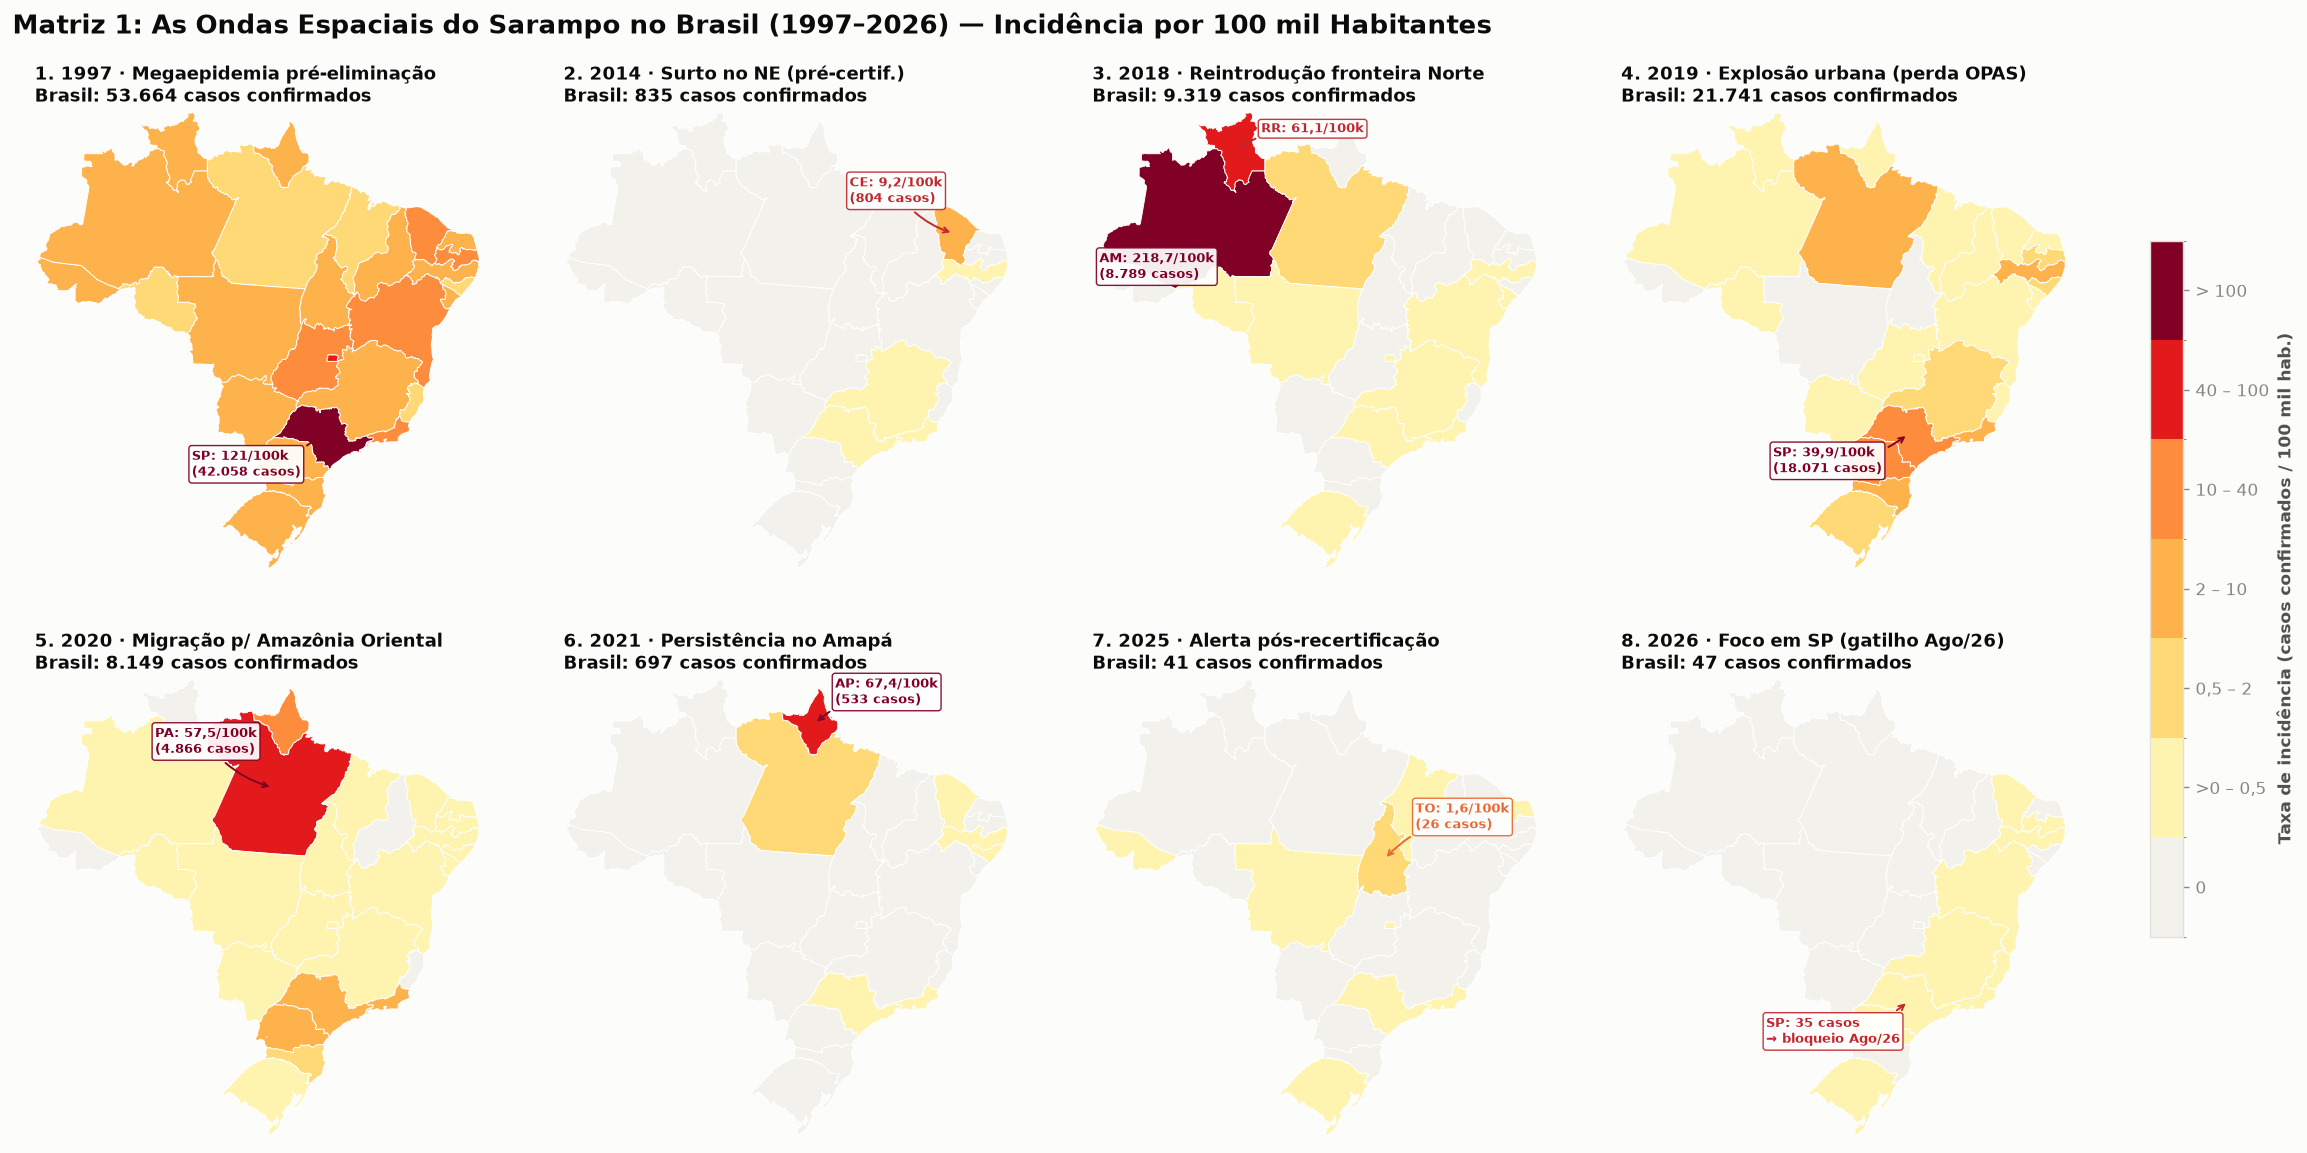

In [ ]:
# Calcula taxa de incidência anual por 100.000 habitantes usando a população anual do próprio ano
pop_piv = pop_uf_ano[pop_uf_ano["uf"].isin(SIGLAS)].pivot_table(index="uf", columns="ano", values="populacao_total")
pop_piv[2026] = pop_piv[2025]  # população SVS vai até 2025; repete 2025 para 2026

casos_uf = serie_casos[serie_casos["nivel"] == "uf"].copy()
casos_uf["pop"] = [
    pop_piv.loc[r["codigo"], r["ano"]] if (r["codigo"] in pop_piv.index and r["ano"] in pop_piv.columns) else np.nan
    for _, r in casos_uf.iterrows()
]
casos_uf["inc_100k"] = casos_uf["casos_confirmados"] / casos_uf["pop"] * 100_000
inc_piv = casos_uf.pivot(index="codigo", columns="ano", values="inc_100k")
abs_piv = casos_uf.pivot(index="codigo", columns="ano", values="casos_confirmados")

anos_marco = [
    (1997, "1997 · Megaepidemia pré-eliminação"),
    (2014, "2014 · Surto no NE (pré-certif.)"),
    (2018, "2018 · Reintrodução fronteira Norte"),
    (2019, "2019 · Explosão urbana (perda OPAS)"),
    (2020, "2020 · Migração p/ Amazônia Oriental"),
    (2021, "2021 · Persistência no Amapá"),
    (2025, "2025 · Alerta pós-recertificação"),
    (2026, "2026 · Foco em SP (gatilho Ago/26)"),
]

# Escala logarítmica discreta compartilhada (zero separado em cinza-claro)
bins_inc = [0, 0.0001, 0.5, 2.0, 10.0, 40.0, 100.0, 250.0]
cores_inc = ["#f2f1eb", "#fff3b0", "#fed976", "#feb24c", "#fd8d3c", "#e31a1c", "#800026"]
cmap_inc = mcolors.ListedColormap(cores_inc)
norm_inc = mcolors.BoundaryNorm(bins_inc, cmap_inc.N)

fig, axes = plt.subplots(2, 4, figsize=(19, 9.6))
axes = axes.ravel()

for i, (ano, titulo) in enumerate(anos_marco):
    ax = axes[i]
    vals = inc_piv[ano].fillna(0).to_dict()
    tot_ano = int(abs_piv[ano].sum())
    coropletico(ax, vals, norm=norm_inc, cmap=cmap_inc, colorbar=False,
                titulo=f"{i+1}. {titulo}", subtitulo=f"Brasil: {tot_ano:,} casos confirmados".replace(",", "."))
    if ano == 1997:
        anotacao(ax, "SP", "SP: 121/100k\n(42.058 casos)", xytext=(-75, -24), cor="#800026", fontsize=7.6)
    elif ano == 2014:
        anotacao(ax, "CE", "CE: 9,2/100k\n(804 casos)", xytext=(-60, 18), cor=RED, fontsize=7.6)
    elif ano == 2018:
        anotacao(ax, "AM", "AM: 218,7/100k\n(8.789 casos)", xytext=(-58, -32), cor="#800026", fontsize=7.6)
        anotacao(ax, "RR", "RR: 61,1/100k", xytext=(14, 10), cor=RED, fontsize=7.4)
    elif ano == 2019:
        anotacao(ax, "SP", "SP: 39,9/100k\n(18.071 casos)", xytext=(-78, -22), cor="#800026", fontsize=7.6)
    elif ano == 2020:
        anotacao(ax, "PA", "PA: 57,5/100k\n(4.866 casos)", xytext=(-68, 20), cor="#800026", fontsize=7.6)
    elif ano == 2021:
        anotacao(ax, "AP", "AP: 67,4/100k\n(533 casos)", xytext=(12, 12), cor="#800026", fontsize=7.6)
    elif ano == 2025:
        anotacao(ax, "TO", "TO: 1,6/100k\n(26 casos)", xytext=(18, 18), cor=ORANGE, fontsize=7.6)
    elif ano == 2026:
        anotacao(ax, "SP", "SP: 35 casos\n→ bloqueio Ago/26", xytext=(-82, -24), cor=RED, fontsize=7.6)

fig.subplots_adjust(left=0.02, right=0.90, top=0.89, bottom=0.03, hspace=0.22, wspace=0.05)
cax = fig.add_axes([0.92, 0.20, 0.014, 0.58])
sm = plt.cm.ScalarMappable(cmap=cmap_inc, norm=norm_inc)
cb = fig.colorbar(sm, cax=cax, ticks=[0.00005, 0.25, 1.25, 6.0, 25.0, 70.0, 175.0])
cb.ax.set_yticklabels(["0", ">0 – 0,5", "0,5 – 2", "2 – 10", "10 – 40", "40 – 100", "> 100"])
cb.set_label("Taxa de incidência (casos confirmados / 100 mil hab.)", fontsize=10, fontweight="bold")

fig.suptitle("Matriz 1: As Ondas Espaciais do Sarampo no Brasil (1997–2026) — Incidência por 100 mil Habitantes",
             x=0.02, y=0.97, ha="left", fontweight="bold", fontsize=15)
plt.show()

br_resumo = serie_casos[(serie_casos["nivel"] == "brasil") & (serie_casos["ano"].isin([a for a, _ in anos_marco]))]
print("Resumo Brasil nos 8 anos-marco:")
print(br_resumo[["ano", "casos_confirmados", "obitos", "fonte"]].to_string(index=False))

## 3. Matriz 2 (Dimensão Política & Governança do PNI): 4 Ciclos da Cobertura Vacinal Real (2013–2026)

### O Contexto Político-Institucional da Imunização no Brasil
Diferente do volume absoluto de doses, a tabela `gold_serie_cobertura_uf_ano.parquet` mede a **cobertura vacinal real de crianças de 1 ano (metodologia oficial PNI/SINASC)** frente à **meta epidemiológica de 95%** necessária para imunidade de rebanho contra o sarampo (doença com $R_0$ entre 12 e 18).

Agrupamos a série em **4 ciclos político-sanitários**:
1. **2013–2015 (Consolidação & Implantação da D2/SCRV):** A 1ª dose superava a meta em quase todo o país (mediana 105,9%; 25 de 27 UFs ≥ 95% em 2014), culminando no certificado de eliminação da OPAS em 2016.
2. **2016–2018 (Austeridade Fiscal / EC 95 & Desmobilização Pré-Surto):** A cobertura D1 cai abaixo da meta na maioria dos estados (em 2017, apenas 4 de 27 UFs atingem 95%; AM cai para 79,8% e PA para 67,5%), criando o bolsão de suscetíveis que alimentou o surto de 2018–2019.
3. **2019–2022 (Pandemia COVID-19, Polarização Política & Crise do PNI):** Colapso inédito na série histórica — em **2020, 2021 e 2022, ZERO de 27 estados** atingiram a meta de 95% (em 2021, a mediana da D2 despencou para **45,3%**, chegando a 25,9% no Acre).
4. **2023–2026 (Reconstrução / Movimento Nacional pela Vacinação & Recertificação OPAS 2024):** Forte retomada da D2 (+36 p.p. na mediana entre 2021 e 2026) e da D1 (91,3% em 2026), mas com **assimetria federativa persistente** na Amazônia Legal e no Rio de Janeiro.

### Decisão Visual
Grade **2×4** (Linha 1 = **1ª Dose D1**; Linha 2 = **2ª Dose D2**) com **escala divergente (`RdYlBu`) centrada rigorosamente na meta oficial de 95%**: qualquer tom quente (amarelo/laranja/vermelho) sinaliza **déficit imunitário abaixo da meta**; azul sinaliza **meta atingida**.


Resumo D1 — UFs atingindo meta >=95%:
  2014: 25/27 UFs | mediana=112.5% | menor=PI (93.1%) | maior=RO (146.9%)
  2017:  4/27 UFs | mediana=83.8% | menor=PA (67.5%) | maior=RO (103.0%)
  2021:  0/27 UFs | mediana=76.5% | menor=RJ (59.5%) | maior=SC (87.5%)
  2024:  1/27 UFs | mediana=87.3% | menor=RJ (72.3%) | maior=MG (95.6%)
  2026:  5/27 UFs | mediana=91.3% | menor=AP (76.4%) | maior=AL (97.8%)

Resumo D2 — UFs atingindo meta >=95%:
  2014:  8/27 UFs | mediana=91.1% | menor=AC (61.6%) | maior=CE (128.3%)
  2017:  0/27 UFs | mediana=69.7% | menor=RN (50.7%) | maior=RR (86.3%)
  2021:  0/27 UFs | mediana=45.3% | menor=AC (25.9%) | maior=SC (69.6%)
  2024:  2/27 UFs | mediana=85.3% | menor=AC (48.4%) | maior=PR (99.9%)
  2026:  0/27 UFs | mediana=81.5% | menor=RR (63.5%) | maior=CE (91.5%)


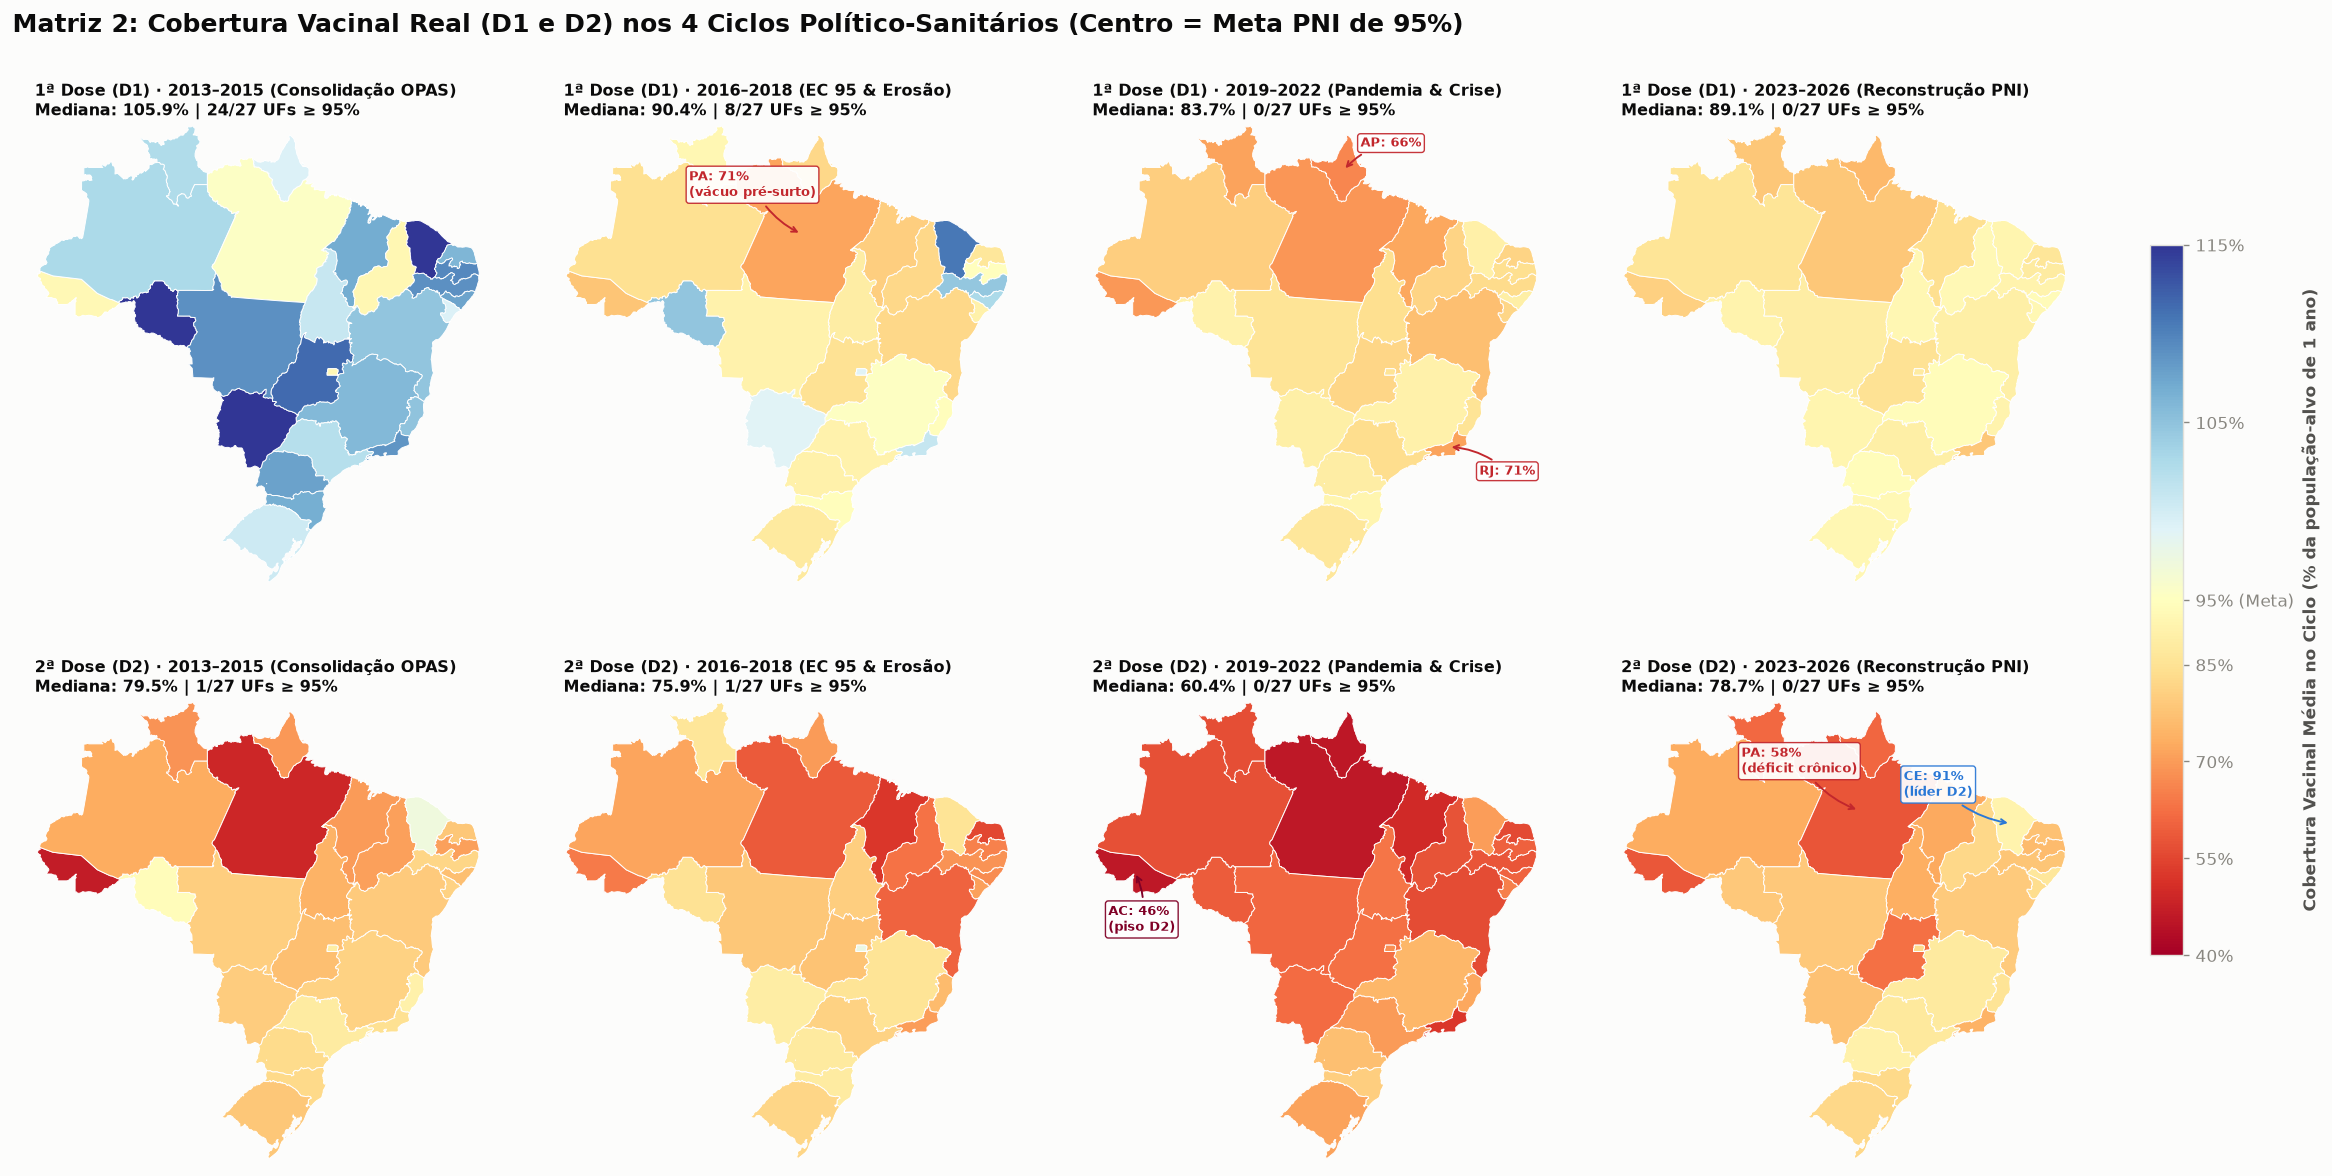

In [ ]:
cob_uf = serie_cob[serie_cob["uf"].isin(SIGLAS)].copy()

ciclos = [
    ("2013–2015", "Consolidação OPAS", 2013, 2015),
    ("2016–2018", "EC 95 & Erosão", 2016, 2018),
    ("2019–2022", "Pandemia & Crise", 2019, 2022),
    ("2023–2026", "Reconstrução PNI", 2023, 2026),
]

# Escala divergente estritamente centrada na meta oficial do PNI (95%)
norm_meta = mcolors.TwoSlopeNorm(vcenter=95.0, vmin=40.0, vmax=115.0)
cmap_meta = plt.get_cmap("RdYlBu")

fig, axes = plt.subplots(2, 4, figsize=(19, 9.8))

for col_idx, (periodo, rotulo, a0, a1) in enumerate(ciclos):
    for row_idx, (dose, nome_dose) in enumerate([("d1", "1ª Dose (D1)"), ("d2", "2ª Dose (D2)")]):
        ax = axes[row_idx, col_idx]
        s = cob_uf[(cob_uf["dose"] == dose) & (cob_uf["ano"].between(a0, a1))].groupby("uf")["cobertura_percentual"].mean()
        n_meta = int((s >= 95.0).sum())
        coropletico(
            ax, s.to_dict(), norm=norm_meta, cmap=cmap_meta, colorbar=False,
            titulo=f"{nome_dose} · {periodo} ({rotulo})",
            subtitulo=f"Mediana: {s.median():.1f}% | {n_meta}/27 UFs ≥ 95%",
            titulo_fs=9.4,
        )
        # Anotações direcionadas nos pontos de ruptura
        if dose == "d1" and a0 == 2016:
            anotacao(ax, "PA", f"PA: {s['PA']:.0f}%\n(vácuo pré-surto)", xytext=(-65, 22), cor=RED, fontsize=7.5)
        elif dose == "d1" and a0 == 2019:
            anotacao(ax, "AP", f"AP: {s['AP']:.0f}%", xytext=(10, 14), cor=RED, fontsize=7.5)
            anotacao(ax, "RJ", f"RJ: {s['RJ']:.0f}%", xytext=(18, -16), cor=RED, fontsize=7.5)
        elif dose == "d2" and a0 == 2019:
            anotacao(ax, "AC", f"AC: {s['AC']:.0f}%\n(piso D2)", xytext=(-15, -34), cor="#800026", fontsize=7.5)
        elif dose == "d2" and a0 == 2023:
            anotacao(ax, "CE", f"CE: {s['CE']:.0f}%\n(líder D2)", xytext=(-62, 16), cor=BLUE, fontsize=7.5)
            anotacao(ax, "PA", f"PA: {s['PA']:.0f}%\n(déficit crônico)", xytext=(-68, 22), cor=RED, fontsize=7.5)

fig.subplots_adjust(left=0.02, right=0.90, top=0.88, bottom=0.03, hspace=0.24, wspace=0.05)
cax = fig.add_axes([0.92, 0.20, 0.014, 0.58])
sm = plt.cm.ScalarMappable(cmap=cmap_meta, norm=norm_meta)
cb = fig.colorbar(sm, cax=cax, ticks=[40, 55, 70, 85, 95, 105, 115])
cb.ax.set_yticklabels(["40%", "55%", "70%", "85%", "95% (Meta)", "105%", "115%"])
cb.set_label("Cobertura Vacinal Média no Ciclo (% da população-alvo de 1 ano)", fontsize=10, fontweight="bold")

fig.suptitle("Matriz 2: Cobertura Vacinal Real (D1 e D2) nos 4 Ciclos Político-Sanitários (Centro = Meta PNI de 95%)",
             x=0.02, y=0.97, ha="left", fontweight="bold", fontsize=14.5)
plt.show()

# Quadro-resumo dos piores e melhores anos isolados (2014 vs 2021 vs 2026)
for dose in ["d1", "d2"]:
    piv = cob_uf[cob_uf["dose"] == dose].pivot(index="uf", columns="ano", values="cobertura_percentual")
    print(f"\nResumo {dose.upper()} — UFs atingindo meta >=95%:")
    for ano in [2014, 2017, 2021, 2024, 2026]:
        s = piv[ano].dropna()
        print(f"  {ano}: {(s >= 95).sum():2d}/27 UFs | mediana={s.median():.1f}% | menor={s.idxmin()} ({s.min():.1f}%) | maior={s.idxmax()} ({s.max():.1f}%)")

## 4. Matriz 3 (Cruzamento Político & Socioeconômico): A Inversão do Gradiente entre 2021 e 2026

### Hipótese Investigada
Um pressuposto frequente em saúde pública é que **estados mais ricos sempre têm melhor cobertura vacinal**. O cruzamento dos dados oficiais do **IBGE (SIDRA / PNAD Contínua Anual 2025)** e do **TSE (Dados Abertos, 2º turno presidencial 2022)** com a cobertura nominal do PNI revela uma **inversão estrutural notável entre a crise (2021) e a reconstrução (2026)**:

1. **No fundo do poço da crise (2021):** A cobertura acompanhava a renda ($r = +0{,}53$ na D1). Estados mais ricos (Sul/Sudeste/CO) resistiram melhor, enquanto Norte e Nordeste despencaram.
2. **Na recuperação (2021 → 2026):** O gradiente **inverteu-se completamente**! A recuperação da D1 teve **correlação negativa com a renda ($r = -0{,}55$)** e **correlação positiva forte com o alinhamento eleitoral ao bloco vencedor de 2022 ($r = +0{,}56$)**.
3. **O papel decisivo da governança municipal (Homogeneidade ≥ 95%):** Em 2026, o bloco de estados onde Lula venceu em 2022 — apesar de ter **renda domiciliar per capita 35% menor** (R\$ 1.594 vs. R\$ 2.453) — alcançou **47,1% dos municípios batendo a meta da D2 ≥ 95%**, contra **33,0%** no outro bloco (com destaque para **CE 79,3%**, **PE 64,0%** e **AL 56,9%**).
4. **Por que o mapa coroplético supera médias agregadas?** A grade 2×3 mostra imediatamente a **fratura entre Norte e Nordeste** dentro do grupo de baixa renda: enquanto o Nordeste lidera a homogeneidade municipal, a Amazônia Legal (AC, AP, PA, RR) e o **Rio de Janeiro** (alta renda, mas apenas 15,1% dos municípios na meta!) permanecem como gargalos críticos.

Média por bloco eleitoral (2022):
                              renda  d1_2021  d1_2026  recup_d1  d2_2026  homog_d2  pct_priv
bloco_2022                                                                                  
Vitória Bolsonaro (14 UFs)  2453.29    76.29    88.93     12.64    78.21     33.02      1.04
Vitória Lula (13 UFs)       1594.38    72.87    91.07     18.20    82.07     47.12      0.44


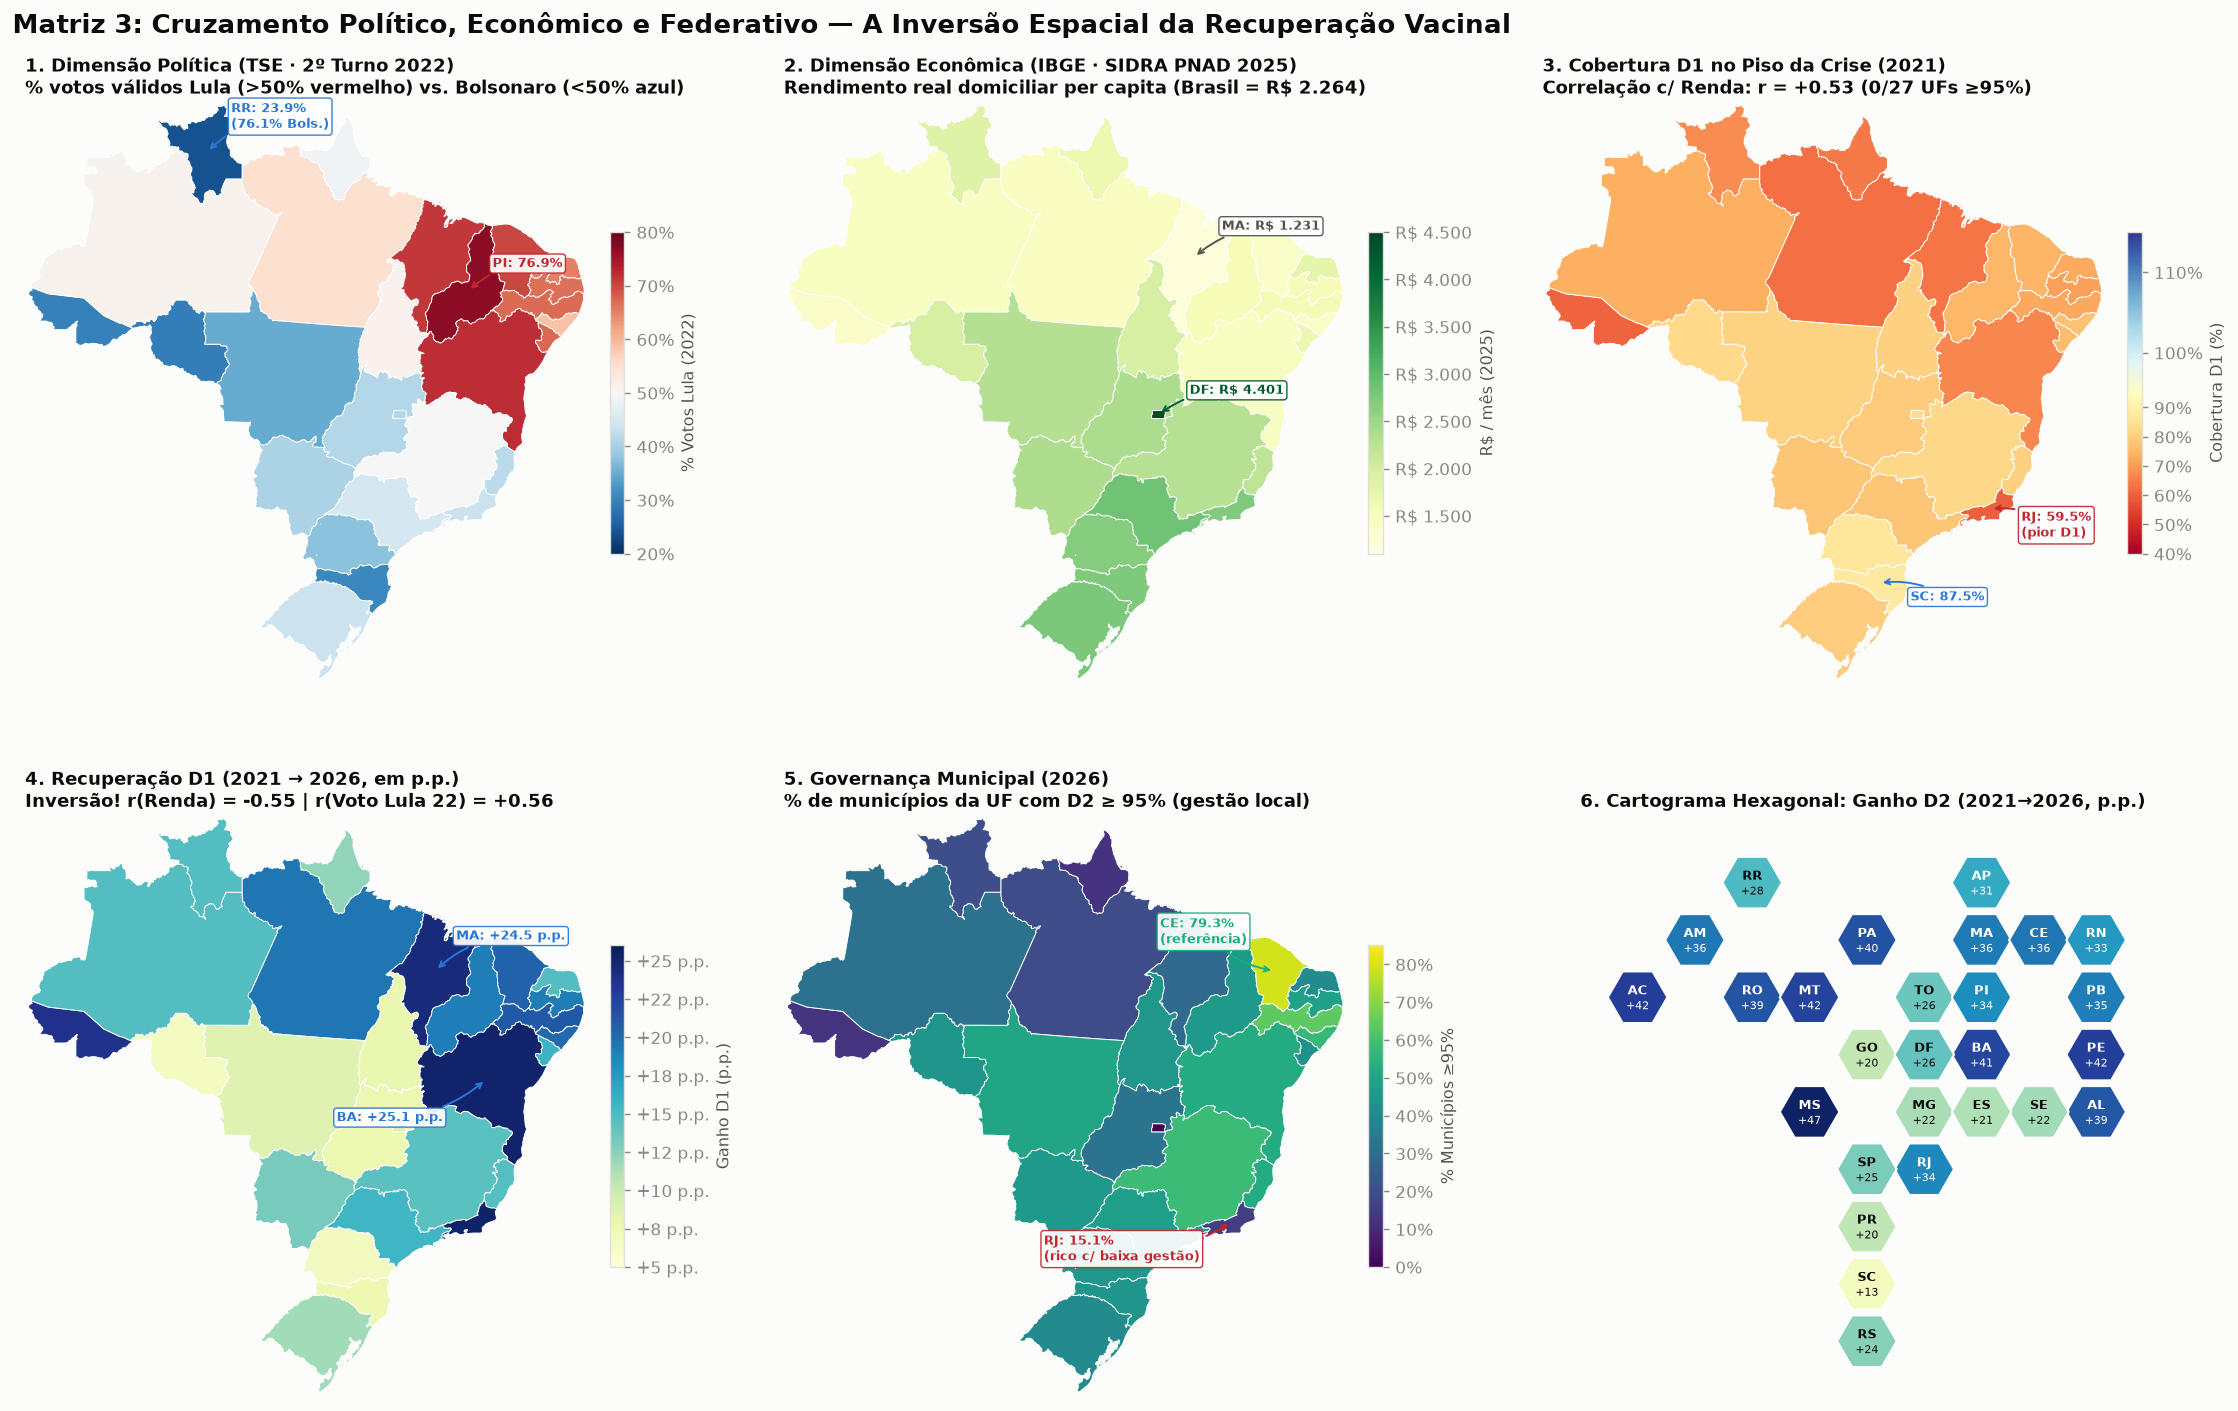

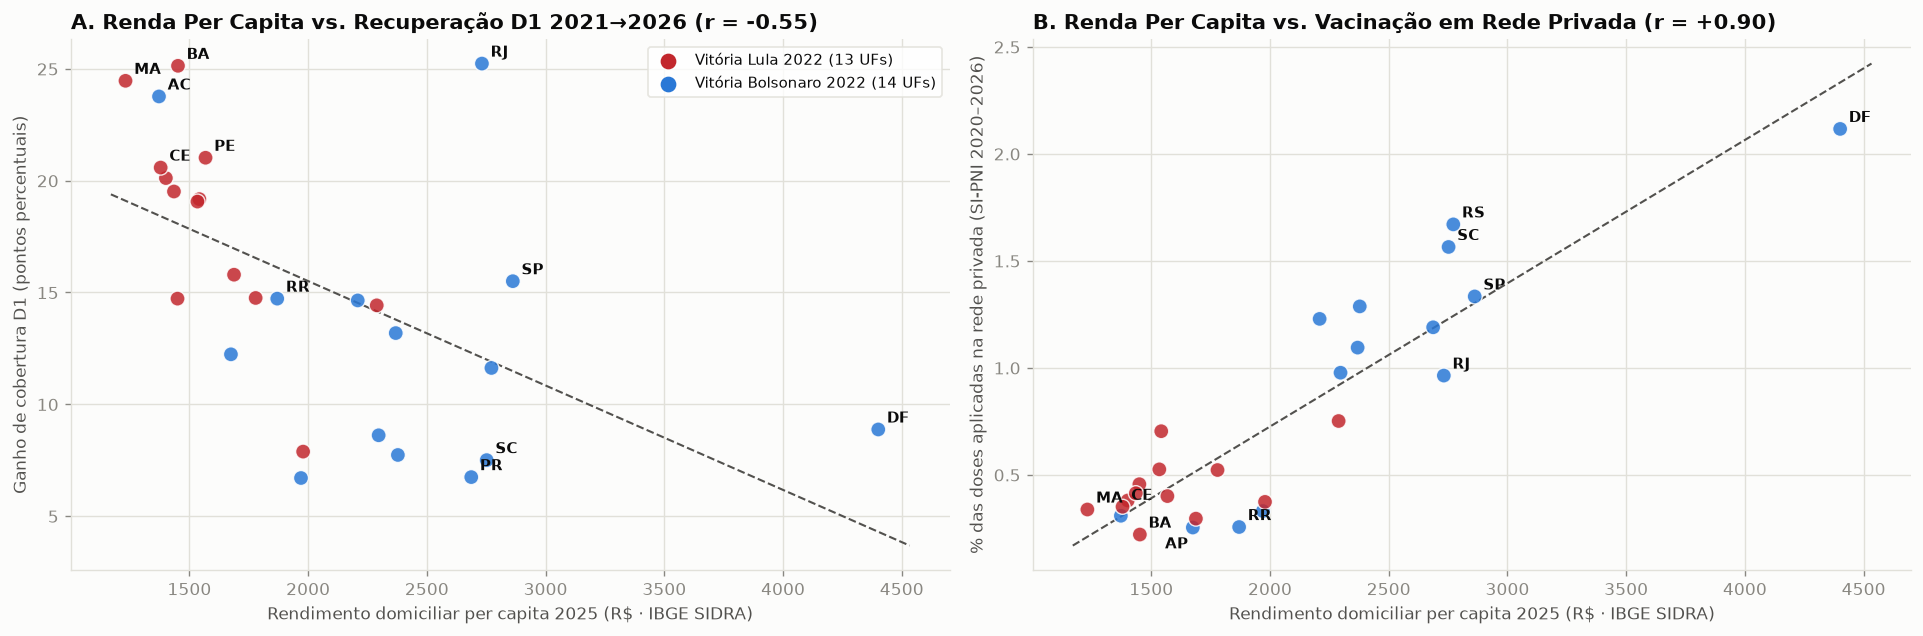

In [ ]:
d1_piv = cob_uf[cob_uf["dose"] == "d1"].pivot(index="uf", columns="ano", values="cobertura_percentual")
d2_piv = cob_uf[cob_uf["dose"] == "d2"].pivot(index="uf", columns="ano", values="cobertura_percentual")

recup_d1 = (d1_piv[2026] - d1_piv[2021]).reindex(SIGLAS)
recup_d2 = (d2_piv[2026] - d2_piv[2021]).reindex(SIGLAS)

# Homogeneidade municipal oficial: % de municípios da UF com cobertura D2 >= 95% em 2026
cob_m = cob_mun.copy()
cob_m["uf"] = cob_m["codigo_uf"].map(ID_STR_PARA_SIGLA)
homog_d2_2026 = (
    cob_m[(cob_m["ano"] == 2026) & (cob_m["uf"].isin(SIGLAS))]
    .groupby("uf")["cobertura_d2_percentual"]
    .apply(lambda s: (s >= 95.0).mean() * 100)
    .reindex(SIGLAS)
)

fig, axes = plt.subplots(2, 3, figsize=(18.5, 11.8))

# Painel 1: Alinhamento Político-Eleitoral (TSE 2022)
norm_voto = mcolors.TwoSlopeNorm(vcenter=50.0, vmin=20.0, vmax=80.0)
coropletico(axes[0, 0], VOTO_LULA_2022.to_dict(), norm=norm_voto, cmap="RdBu_r",
            titulo="1. Dimensão Política (TSE · 2º Turno 2022)",
            subtitulo="% votos válidos Lula (>50% vermelho) vs. Bolsonaro (<50% azul)",
            rotulo="% Votos Lula (2022)", fmt="{:.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[0, 0], "PI", f"PI: {VOTO_LULA_2022['PI']:.1f}%", xytext=(14, 14), cor=RED, fontsize=7.6)
anotacao(axes[0, 0], "RR", f"RR: {VOTO_LULA_2022['RR']:.1f}%\n({100-VOTO_LULA_2022['RR']:.1f}% Bols.)", xytext=(14, 14), cor=BLUE, fontsize=7.5)

# Painel 2: Rendimento Domiciliar Per Capita (IBGE SIDRA PNAD 2025)
norm_renda = mcolors.Normalize(vmin=1100, vmax=4500)
coropletico(axes[0, 1], RENDA_IBGE.to_dict(), norm=norm_renda, cmap="YlGn",
            titulo="2. Dimensão Econômica (IBGE · SIDRA PNAD 2025)",
            subtitulo=f"Rendimento real domiciliar per capita (Brasil = R$ {RENDA_BR_2025:,.0f})".replace(",", "."),
            rotulo="R$ / mês (2025)", fmt="R$ {:,.0f}", cbar_kw={"shrink": 0.55})
anotacao(axes[0, 1], "DF", f"DF: R$ {RENDA_IBGE['DF']:,.0f}".replace(",", "."), xytext=(18, 12), cor="#005a32", fontsize=7.6)
anotacao(axes[0, 1], "MA", f"MA: R$ {RENDA_IBGE['MA']:,.0f}".replace(",", "."), xytext=(16, 16), cor=TEXT_SECONDARY, fontsize=7.6)

# Painel 3: Cobertura D1 na Crise (2021)
coropletico(axes[0, 2], d1_piv[2021].reindex(SIGLAS).to_dict(), norm=norm_meta, cmap="RdYlBu",
            titulo="3. Cobertura D1 no Piso da Crise (2021)",
            subtitulo=f"Correlação c/ Renda: r = +{RENDA_IBGE.corr(d1_piv[2021].reindex(SIGLAS)):.2f} (0/27 UFs ≥95%)",
            rotulo="Cobertura D1 (%)", fmt="{:.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[0, 2], "RJ", f"RJ: {d1_piv.loc['RJ', 2021]:.1f}%\n(pior D1)", xytext=(18, -16), cor=RED, fontsize=7.6)
anotacao(axes[0, 2], "SC", f"SC: {d1_piv.loc['SC', 2021]:.1f}%", xytext=(18, -10), cor=BLUE, fontsize=7.6)

# Painel 4: Recuperação D1 (2021 -> 2026) — INVERSÃO DO GRADIENTE
norm_rec = mcolors.Normalize(vmin=5, vmax=26)
r_renda = RENDA_IBGE.corr(recup_d1)
r_voto = VOTO_LULA_2022.corr(recup_d1)
coropletico(axes[1, 0], recup_d1.to_dict(), norm=norm_rec, cmap="YlGnBu",
            titulo="4. Recuperação D1 (2021 → 2026, em p.p.)",
            subtitulo=f"Inversão! r(Renda) = {r_renda:+.2f} | r(Voto Lula 22) = {r_voto:+.2f}",
            rotulo="Ganho D1 (p.p.)", fmt="+{:.0f} p.p.", cbar_kw={"shrink": 0.55})
anotacao(axes[1, 0], "BA", f"BA: +{recup_d1['BA']:.1f} p.p.", xytext=(-86, -24), cor=BLUE, fontsize=7.6)
anotacao(axes[1, 0], "MA", f"MA: +{recup_d1['MA']:.1f} p.p.", xytext=(12, 18), cor=BLUE, fontsize=7.6)

# Painel 5: Homogeneidade Municipal (D2 >= 95% em 2026)
norm_hom = mcolors.Normalize(vmin=0, vmax=85)
coropletico(axes[1, 1], homog_d2_2026.to_dict(), norm=norm_hom, cmap="viridis",
            titulo="5. Governança Municipal (2026)",
            subtitulo="% de municípios da UF com D2 ≥ 95% (gestão local)",
            rotulo="% Municípios ≥95%", fmt="{:.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[1, 1], "CE", f"CE: {homog_d2_2026['CE']:.1f}%\n(referência)", xytext=(-66, 16), cor=GREEN, fontsize=7.6)
anotacao(axes[1, 1], "RJ", f"RJ: {homog_d2_2026['RJ']:.1f}%\n(rico c/ baixa gestão)", xytext=(-108, -22), cor=RED, fontsize=7.5)

# Painel 6: Cartograma Hexagonal da Recuperação D2 (2021 -> 2026)
norm_recd2 = mcolors.Normalize(vmin=10, vmax=48)
cartograma_hexagonal(axes[1, 2], recup_d2.to_dict(), norm=norm_recd2, cmap="YlGnBu",
                     titulo="6. Cartograma Hexagonal: Ganho D2 (2021→2026, p.p.)",
                     fmt="+{:.0f}")

fig.subplots_adjust(left=0.02, right=0.98, top=0.91, bottom=0.03, hspace=0.22, wspace=0.08)
fig.suptitle("Matriz 3: Cruzamento Político, Econômico e Federativo — A Inversão Espacial da Recuperação Vacinal",
             x=0.02, y=0.97, ha="left", fontweight="bold", fontsize=15)
plt.show()

# Painel analítico complementar (2 scatterplots para validação quantitativa das correlações)
est_uf = estab[estab["uf_estabelecimento"].isin(SIGLAS)]
tot_e = est_uf.groupby("uf_estabelecimento")["doses"].sum()
priv_e = est_uf[
    est_uf["natureza_estabelecimento"].isin(["ENTIDADES EMPRESARIAIS", "PESSOAS FISICAS"])
    | (est_uf["estrategia_vacinacao"] == "Serviço Privado")
].groupby("uf_estabelecimento")["doses"].sum()
pct_priv = (priv_e / tot_e * 100).reindex(SIGLAS).fillna(0)

df_cross = pd.DataFrame({
    "renda": RENDA_IBGE,
    "gini": GINI_IBGE,
    "voto_lula": VOTO_LULA_2022,
    "recup_d1": recup_d1,
    "recup_d2": recup_d2,
    "homog_d2": homog_d2_2026,
    "pct_priv": pct_priv,
    "d1_2021": d1_piv[2021].reindex(SIGLAS),
    "d1_2026": d1_piv[2026].reindex(SIGLAS),
    "d2_2026": d2_piv[2026].reindex(SIGLAS),
})

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
cores_pts = [RED if v >= 50 else BLUE for v in df_cross["voto_lula"]]

# Scatter A: Renda vs Recuperação D1 (2021->2026)
axes[0].scatter(df_cross["renda"], df_cross["recup_d1"], c=cores_pts, s=75, alpha=0.85, edgecolors="white", lw=0.8, zorder=3)
z = np.polyfit(df_cross["renda"], df_cross["recup_d1"], 1)
xs = np.linspace(df_cross["renda"].min() * 0.95, df_cross["renda"].max() * 1.03, 50)
axes[0].plot(xs, np.poly1d(z)(xs), linestyle="--", color=TEXT_SECONDARY, lw=1.2, zorder=2)
for uf, r in df_cross.iterrows():
    if uf in ["MA", "BA", "PE", "CE", "AC", "RJ", "SP", "SC", "PR", "DF", "RR"]:
        axes[0].annotate(uf, (r["renda"], r["recup_d1"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, fontweight="bold")
axes[0].set_title(f"A. Renda Per Capita vs. Recuperação D1 2021→2026 (r = {r_renda:+.2f})", loc="left", fontweight="bold")
axes[0].set_xlabel("Rendimento domiciliar per capita 2025 (R$ · IBGE SIDRA)")
axes[0].set_ylabel("Ganho de cobertura D1 (pontos percentuais)")
axes[0].grid(color=GRID)

# Scatter B: Renda vs % Rede Privada (Dependência do SUS)
r_priv = df_cross["renda"].corr(df_cross["pct_priv"])
axes[1].scatter(df_cross["renda"], df_cross["pct_priv"], c=cores_pts, s=75, alpha=0.85, edgecolors="white", lw=0.8, zorder=3)
z2 = np.polyfit(df_cross["renda"], df_cross["pct_priv"], 1)
axes[1].plot(xs, np.poly1d(z2)(xs), linestyle="--", color=TEXT_SECONDARY, lw=1.2, zorder=2)
for uf, r in df_cross.iterrows():
    if uf in ["DF", "RS", "SC", "SP", "RJ", "BA", "MA", "CE", "AP", "RR"]:
        dx, dy = (-16, -12) if uf == "AP" else (5, 4)
        axes[1].annotate(uf, (r["renda"], r["pct_priv"]), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, fontweight="bold")
axes[1].set_title(f"B. Renda Per Capita vs. Vacinação em Rede Privada (r = {r_priv:+.2f})", loc="left", fontweight="bold")
axes[1].set_xlabel("Rendimento domiciliar per capita 2025 (R$ · IBGE SIDRA)")
axes[1].set_ylabel("% das doses aplicadas na rede privada (SI-PNI 2020–2026)")
axes[1].grid(color=GRID)

# Legenda compartilhada dos blocos eleitorais
axes[0].scatter([], [], c=RED, s=65, label="Vitória Lula 2022 (13 UFs)")
axes[0].scatter([], [], c=BLUE, s=65, label="Vitória Bolsonaro 2022 (14 UFs)")
axes[0].legend(frameon=True, facecolor="white", edgecolor=GRID, loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

df_cross["bloco_2022"] = np.where(df_cross["voto_lula"] >= 50, "Vitória Lula (13 UFs)", "Vitória Bolsonaro (14 UFs)")
print("Média por bloco eleitoral (2022):")
print(df_cross.groupby("bloco_2022")[["renda", "d1_2021", "d1_2026", "recup_d1", "d2_2026", "homog_d2", "pct_priv"]].mean().round(2).to_string())

## 5. Matriz 4 (Dimensão Social, Racial e Acesso): As Assimetrias Invisíveis do Sarampo

### Achados Diretos do Cruzamento SI-PNI × SINAN
Além da renda estadual, os próprios microdados do Ministério da Saúde (`gold_estabelecimento`, `gold_perfil` e `gold_sinan_notificacoes`) expõem **quatro clivagens sociais profundas**:

1. **Dependência Quase Absoluta do SUS:** A correlação entre renda e uso de clínicas privadas é de **$r = +0{,}90$**. Enquanto o **DF (2,12%)** e o **RS (1,67%)** têm a maior participação privada, na **Bahia (0,22%)**, **Amapá (0,25%)** e **Roraima (0,26%)** mais de **99,7% das doses** dependem exclusivamente da rede pública.
2. **Apagão Estatístico Racial na Vacinação:** Nos estados mais ricos e populosos do Sudeste — **SP (32,1%)** e **RJ (24,9%)** — quase um terço dos registros do SI-PNI omite raça/cor (`SEM INFORMACAO`), e esse apagão **piorou em anos de megacampanha** (subindo de 10,4% em 2020 para **27,2% em 2026**).
3. **Fronteira Indígena × Gravidade Extrema:** A vacinação indígena concentra-se na Amazônia Legal e no MS (**AM 3,95%**, **RR 3,07%**, **AC 2,46%**, **MS 1,87%**). Ao cruzar com o SINAN (2018–2026), surge o dado social mais contundente do estudo: **61,8% dos indígenas com sarampo confirmado foram hospitalizados**, uma taxa **4,5 vezes maior** do que a observada em pacientes brancos (**13,7%**) e mais de **3,4 vezes maior** que em pardos (**17,9%**) e pretos (**17,2%**).
4. **Vácuo Vacinal Concentrado no Norte:** Nos casos confirmados de 2018–2026 com histórico vacinal conhecido, **todos os 5 estados com maior proporção de doentes não vacinados pertencem à Região Norte**: **AP (86,0%)**, **PA (84,8%)**, **TO (83,3%)**, **RO (77,8%)** e **AM (77,5%)**.

Top 5 UFs com maior % de confirmados NÃO vacinados (2018-2026):
uf
AP    86.0%
PA    84.8%
TO    83.3%
RO    77.8%
AM    77.5%


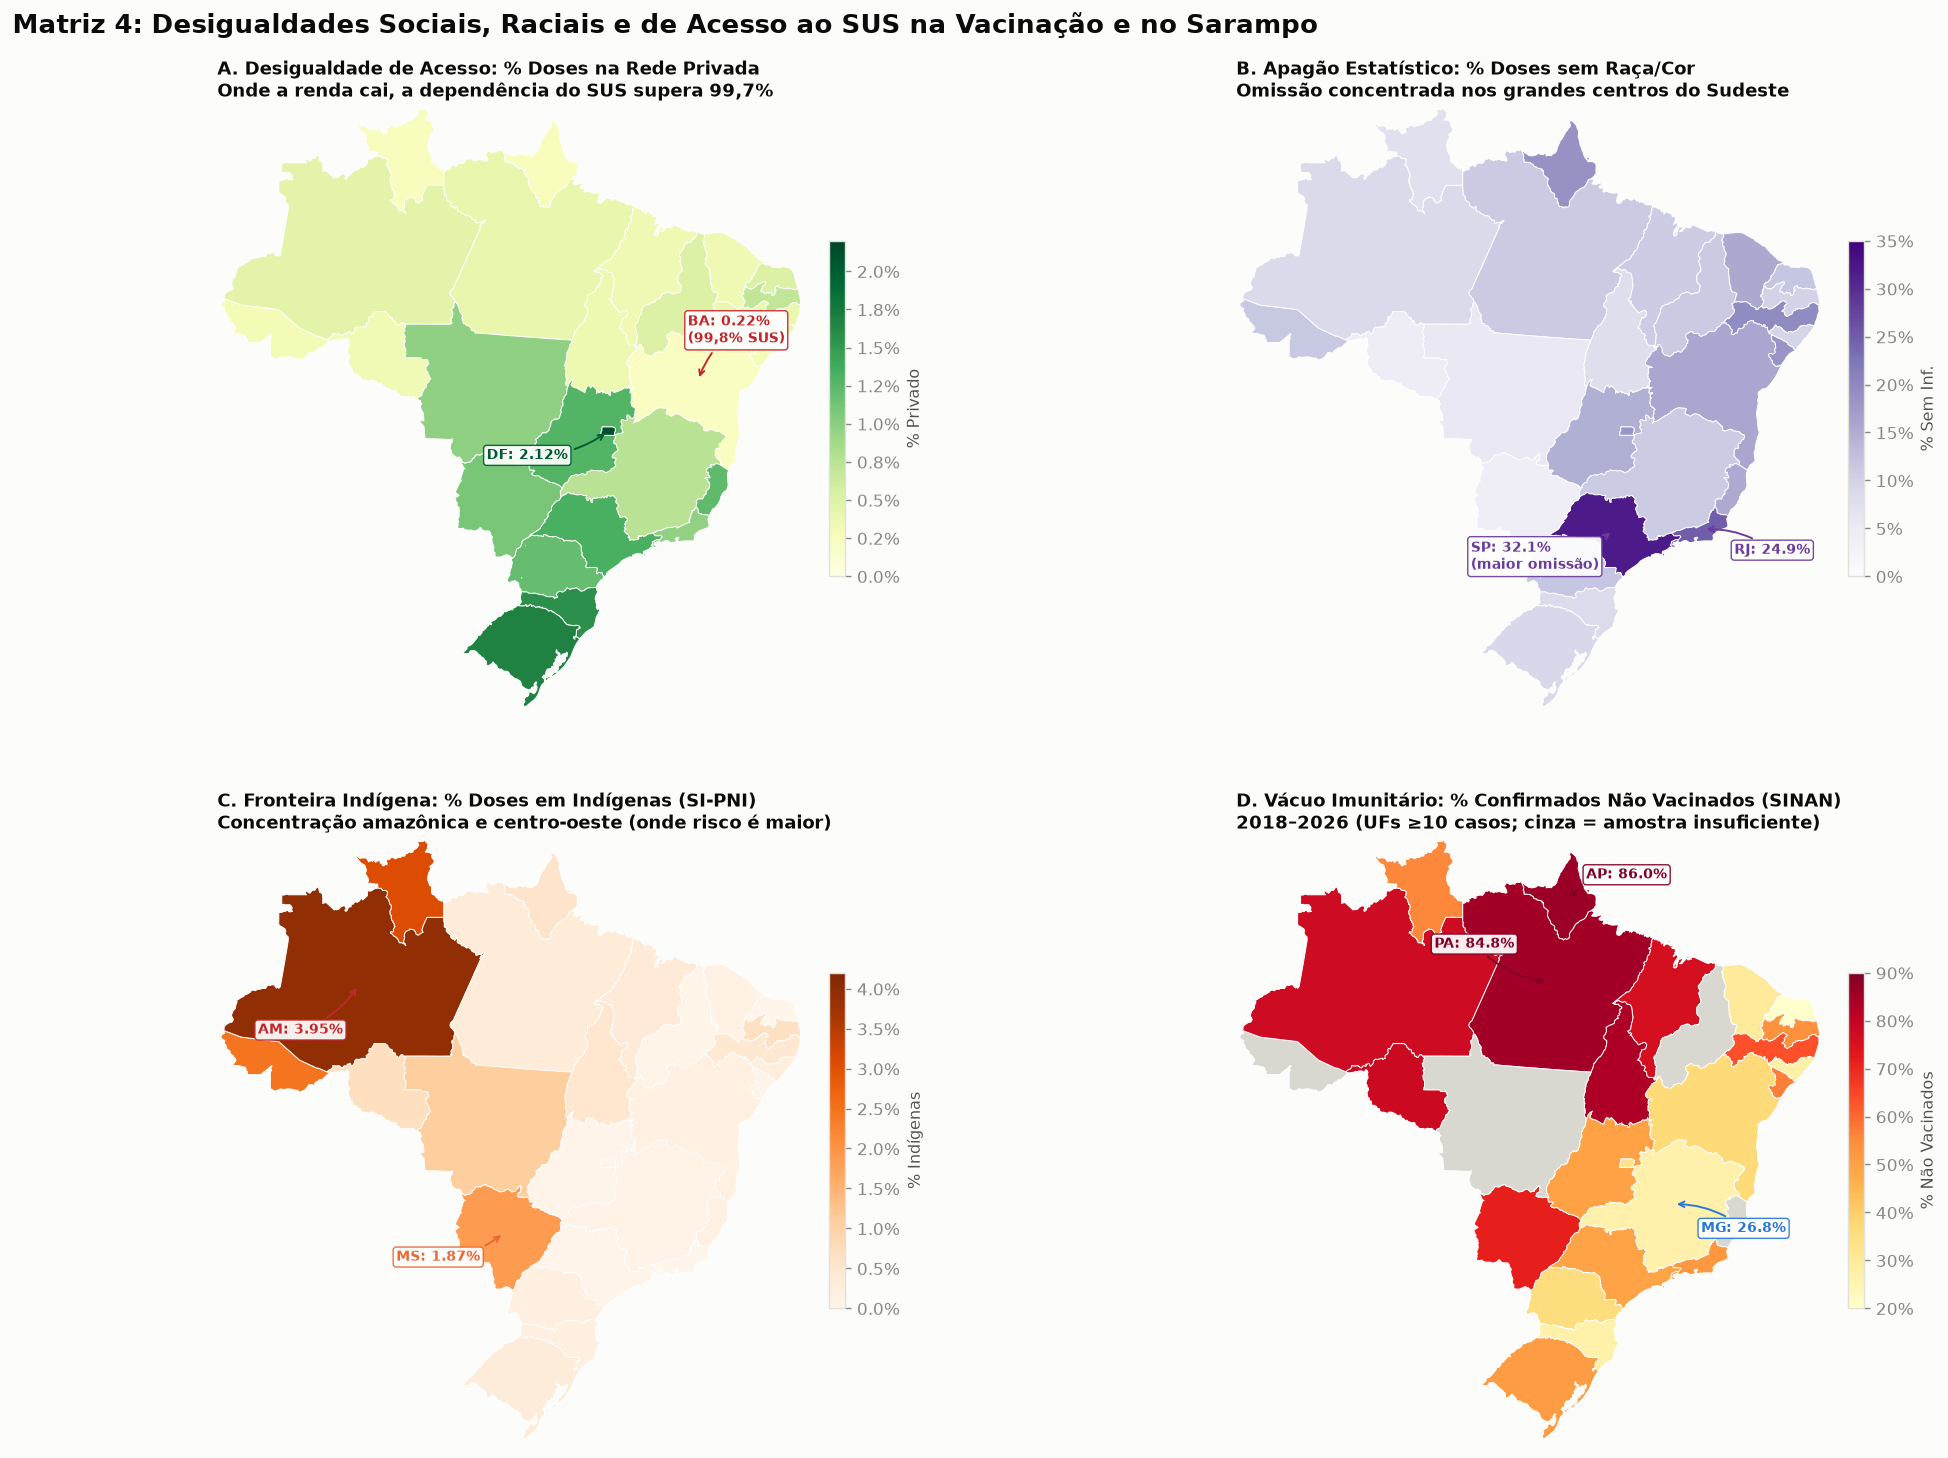

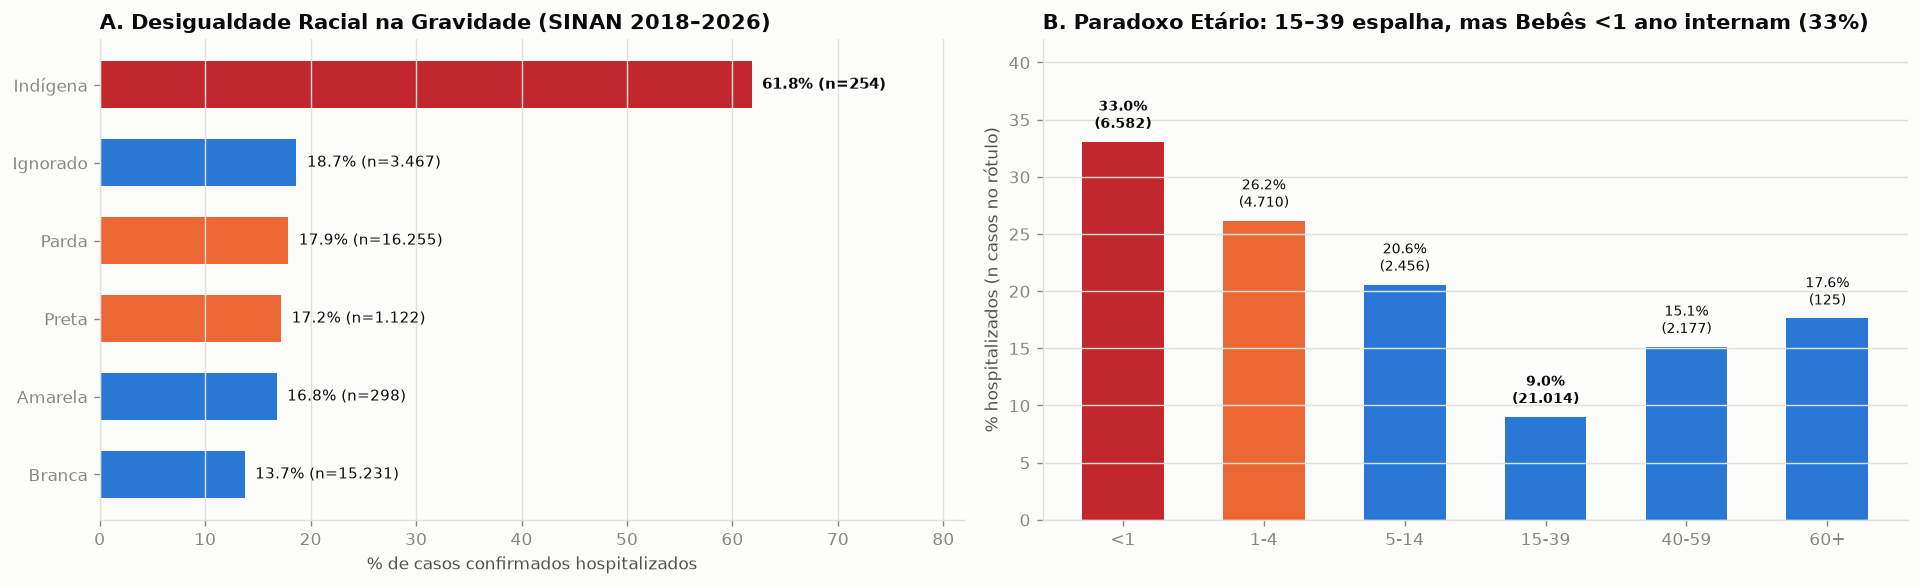

In [ ]:
# 1. % Sem informação de raça/cor e % Indígena na vacinação (2020-2026)
perf_uf = perfil[perfil["uf_paciente"].isin(SIGLAS)]
tot_p = perf_uf.groupby("uf_paciente")["doses"].sum()
pct_sem_raca = (perf_uf[perf_uf["raca_cor_paciente"] == "SEM INFORMACAO"].groupby("uf_paciente")["doses"].sum() / tot_p * 100).reindex(SIGLAS).fillna(0)
pct_indigena = (perf_uf[perf_uf["raca_cor_paciente"] == "INDIGENA"].groupby("uf_paciente")["doses"].sum() / tot_p * 100).reindex(SIGLAS).fillna(0)

# 2. % Não-vacinados entre casos confirmados de sarampo (SINAN 2018-2026; UFs com >= 10 casos)
conf18 = sinan_notif[(sinan_notif["classificacao_final"] == 1) & (sinan_notif["ano_notificacao"] >= 2018)].copy()
conf18["uf"] = conf18["uf_residencia"].fillna(conf18["uf_notificacao"]).map(ID_INT_PARA_SIGLA)
ufs_validas = conf18["uf"].value_counts()
ufs_validas = ufs_validas[ufs_validas >= 10].index

nv_valid = conf18[conf18["uf"].isin(ufs_validas) & conf18["historico_vacinal"].isin([1, 2])]
pct_nao_vac_uf = nv_valid.groupby("uf")["historico_vacinal"].apply(lambda s: (s == 2).mean() * 100)

fig, axes = plt.subplots(2, 2, figsize=(16.5, 12.2))

# Painel A: % Serviço Privado
coropletico(axes[0, 0], pct_priv.to_dict(), norm=mcolors.Normalize(0, 2.2), cmap="YlGn",
            titulo="A. Desigualdade de Acesso: % Doses na Rede Privada",
            subtitulo="Onde a renda cai, a dependência do SUS supera 99,7%",
            rotulo="% Privado", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[0, 0], "DF", f"DF: {pct_priv['DF']:.2f}%", xytext=(-70, -16), cor="#005a32", fontsize=8)
anotacao(axes[0, 0], "BA", f"BA: {pct_priv['BA']:.2f}%\n(99,8% SUS)", xytext=(-6, 22), cor=RED, fontsize=7.8)

# Painel B: % Raça/Cor Sem Informação
coropletico(axes[0, 1], pct_sem_raca.to_dict(), norm=mcolors.Normalize(0, 35), cmap="Purples",
            titulo="B. Apagão Estatístico: % Doses sem Raça/Cor",
            subtitulo="Omissão concentrada nos grandes centros do Sudeste",
            rotulo="% Sem Inf.", fmt="{:.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[0, 1], "SP", f"SP: {pct_sem_raca['SP']:.1f}%\n(maior omissão)", xytext=(-82, -22), cor=PURPLE, fontsize=8)
anotacao(axes[0, 1], "RJ", f"RJ: {pct_sem_raca['RJ']:.1f}%", xytext=(18, -14), cor=PURPLE, fontsize=8)

# Painel C: % População Indígena na Vacinação
coropletico(axes[1, 0], pct_indigena.to_dict(), norm=mcolors.Normalize(0, 4.2), cmap="Oranges",
            titulo="C. Fronteira Indígena: % Doses em Indígenas (SI-PNI)",
            subtitulo="Concentração amazônica e centro-oeste (onde risco é maior)",
            rotulo="% Indígenas", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[1, 0], "AM", f"AM: {pct_indigena['AM']:.2f}%", xytext=(-58, -28), cor=RED, fontsize=8)
anotacao(axes[1, 0], "MS", f"MS: {pct_indigena['MS']:.2f}%", xytext=(-62, -16), cor=ORANGE, fontsize=8)

# Painel D: % Casos Confirmados SEM Vacina (SINAN 2018-2026)
coropletico(axes[1, 1], pct_nao_vac_uf.to_dict(), norm=mcolors.Normalize(20, 90), cmap="YlOrRd",
            titulo="D. Vácuo Imunitário: % Confirmados Não Vacinados (SINAN)",
            subtitulo="2018–2026 (UFs ≥10 casos; cinza = amostra insuficiente)",
            rotulo="% Não Vacinados", fmt="{:.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[1, 1], "AP", f"AP: {pct_nao_vac_uf['AP']:.1f}%", xytext=(12, 12), cor="#800026", fontsize=8)
anotacao(axes[1, 1], "PA", f"PA: {pct_nao_vac_uf['PA']:.1f}%", xytext=(-66, 20), cor="#800026", fontsize=8)
anotacao(axes[1, 1], "MG", f"MG: {pct_nao_vac_uf['MG']:.1f}%", xytext=(16, -16), cor=BLUE, fontsize=8)

fig.subplots_adjust(left=0.02, right=0.98, top=0.91, bottom=0.03, hspace=0.20, wspace=0.06)
fig.suptitle("Matriz 4: Desigualdades Sociais, Raciais e de Acesso ao SUS na Vacinação e no Sarampo",
             x=0.02, y=0.97, ha="left", fontweight="bold", fontsize=15)
plt.show()

# Painel Complementar: Gravidade Clínica (Hospitalização) por Raça/Cor e Faixa Etária (SINAN 2018-2026)
h_val = conf18[conf18["hospitalizado"].isin([1, 2])].copy()
mapa_raca = {1: "Branca", 2: "Preta", 3: "Amarela", 4: "Parda", 5: "Indígena", 9: "Ignorado"}
h_val["raca"] = h_val["raca_cor"].map(mapa_raca)
tab_raca = h_val.groupby("raca")["hospitalizado"].agg(
    casos="count", pct_hosp=lambda s: (s == 1).mean() * 100
).sort_values("pct_hosp")

ordem_idade = ["<1", "1-4", "5-14", "15-39", "40-59", "60+"]
tab_idade = h_val.groupby("faixa_etaria")["hospitalizado"].agg(
    casos="count", pct_hosp=lambda s: (s == 1).mean() * 100
).reindex(ordem_idade)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))

# Barras A: Hospitalização por Raça/Cor
cores_r = [RED if r == "Indígena" else (ORANGE if r in ["Parda", "Preta"] else BLUE) for r in tab_raca.index]
bars = axes[0].barh(tab_raca.index, tab_raca["pct_hosp"], color=cores_r, height=0.6)
for b, (_, row) in zip(bars, tab_raca.iterrows()):
    axes[0].text(b.get_width() + 1.0, b.get_y() + b.get_height() / 2,
                 f"{row['pct_hosp']:.1f}% (n={int(row['casos']):,})".replace(",", "."),
                 va="center", fontsize=8.8, fontweight="bold" if row["pct_hosp"] > 50 else "normal")
axes[0].set_xlim(0, 82)
axes[0].set_xlabel("% de casos confirmados hospitalizados")
axes[0].set_title("A. Desigualdade Racial na Gravidade (SINAN 2018–2026)", loc="left", fontweight="bold")
axes[0].grid(axis="x", color=GRID)

# Barras B: Volume de Casos vs. Taxa de Hospitalização por Faixa Etária
x_idx = np.arange(len(ordem_idade))
bars_i = axes[1].bar(x_idx, tab_idade["pct_hosp"], color=[RED if f == "<1" else (ORANGE if f == "1-4" else BLUE) for f in ordem_idade], width=0.58)
for i, (b, (_, row)) in enumerate(zip(bars_i, tab_idade.iterrows())):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8,
                 f"{row['pct_hosp']:.1f}%\n({int(row['casos']):,})".replace(",", "."),
                 ha="center", va="bottom", fontsize=8.2, fontweight="bold" if ordem_idade[i] in ["<1", "15-39"] else "normal")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(ordem_idade)
axes[1].set_ylim(0, 42)
axes[1].set_ylabel("% hospitalizados (n casos no rótulo)")
axes[1].set_title("B. Paradoxo Etário: 15–39 espalha, mas Bebês <1 ano internam (33%)", loc="left", fontweight="bold")
axes[1].grid(axis="y", color=GRID)

plt.tight_layout()
plt.show()

print("Top 5 UFs com maior % de confirmados NÃO vacinados (2018-2026):")
print(pct_nao_vac_uf.nlargest(5).round(1).map("{:.1f}%".format).to_string())

## 6. Matriz 5 (Dimensão Demográfica): 30 Anos de Transição Demográfica e o "Efeito Denominador"

### Por que a Demografia Muda a Leitura do Sarampo?
Um dos maiores avanços metodológicos trazidos pela camada `data/gold/demografia/` (`SINASC` + `IBGE/POPSVS`) é permitir visualizar **como a população-alvo infantil está mudando radicalmente no espaço e no tempo**:

1. **Encolhimento pela Metade da Base Infantil (1995 → 2025):** Em 30 anos, a proporção de crianças menores de 5 anos na população brasileira caiu de uma mediana estadual de **12,4% em 1995** para apenas **6,2% em 2025** (no Rio de Janeiro, chegou a **5,2%**; em Roraima, ainda é **9,4%**).
2. **Queda Acelerada da Natalidade vs. Choque Migratório (2015 → 2024):** Em apenas 9 anos, os nascidos vivos no Brasil caíram **20,8%** (de 3,02 milhões para 2,39 milhões). As quedas mais drásticas ocorreram nas metrópoles envelhecidas (**RJ -30,9%**, **DF -27,8%**, **SP -25,7%**, **RS -24,5%**). **Roraima foi o único estado brasileiro a apresentar crescimento positivo de nascidos vivos (+5,9%)**, impulsionado pela migração venezuelana — justamente a porta de entrada do sarampo em 2018!
3. **Implicação para Análise Visual de Dados:** Comparar volumes absolutos de doses infantis entre 2005 e 2025 (ou entre RJ e RR) sem corrigir pela coorte anual de nascidos vivos gera distorções severas. O painel 2×3 demonstra essa transformação demográfica lado a lado com a cobertura nominal corrigida pelo SINASC.

Brasil — Nascidos vivos: 3,206,761 (2000) -> 3,017,668 (2015) -> 2,389,325 (2024) [-20.8%]
Maiores quedas de nascidos vivos (2015->2024): {'RJ': '-30.9%', 'DF': '-27.8%', 'SP': '-25.7%', 'RN': '-25.4%', 'RS': '-24.5%'}
Única alta / menores quedas (2015->2024):      {'RR': '+5.9%', 'MT': '-2.4%', 'SC': '-3.5%', 'GO': '-11.7%', 'ES': '-12.3%'}


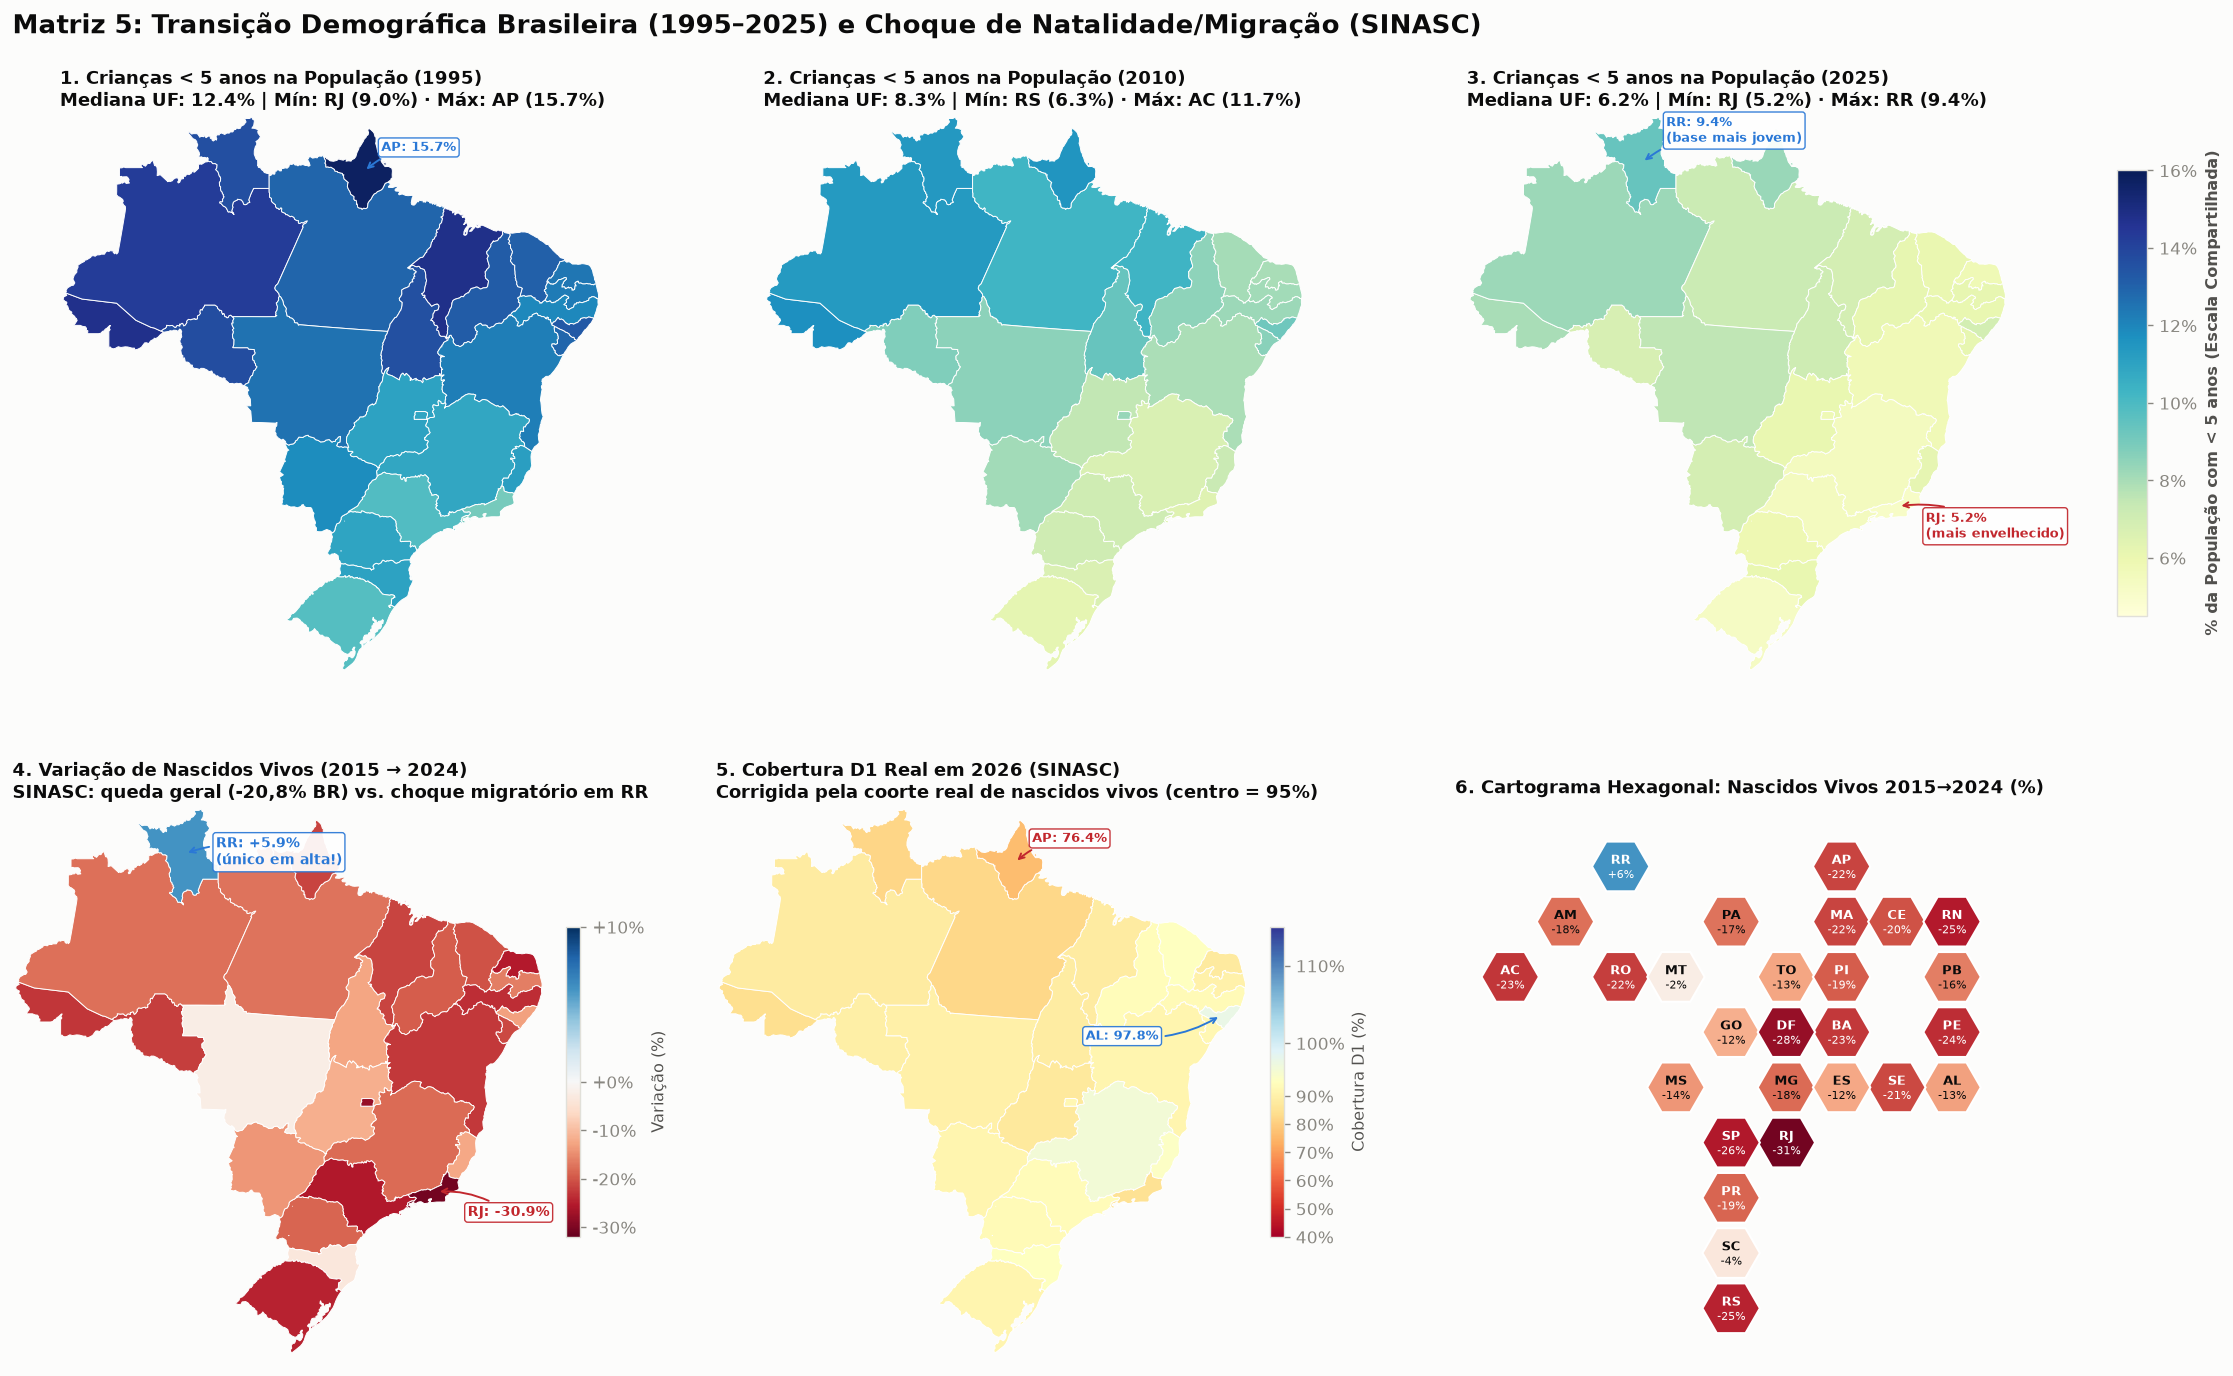

In [ ]:
pop_g = pop_uf_ano[pop_uf_ano["uf"].isin(SIGLAS)].copy()
pop_g["pct_m5"] = pop_g["populacao_menor_5"] / pop_g["populacao_total"] * 100
m5_piv = pop_g.pivot_table(index="uf", columns="ano", values="pct_m5")

# Variação % de nascidos vivos (SINASC 2015 -> 2024)
nv_g = nv_uf_ano[nv_uf_ano["uf"].isin(SIGLAS)].groupby(["uf", "ano"])["nascidos_vivos"].sum().unstack()
var_nv = ((nv_g[2024] / nv_g[2015] - 1) * 100).reindex(SIGLAS)

fig, axes = plt.subplots(2, 3, figsize=(18.5, 11.5))

# Linha Superior: 3 décadas de % crianças < 5 anos com ESCALA COMPARTILHADA
norm_m5 = mcolors.Normalize(vmin=4.5, vmax=16.0)
cmap_m5 = plt.get_cmap("YlGnBu")

for idx, ano in enumerate([1995, 2010, 2025]):
    ax = axes[0, idx]
    s = m5_piv[ano].reindex(SIGLAS)
    coropletico(ax, s.to_dict(), norm=norm_m5, cmap=cmap_m5, colorbar=False,
                titulo=f"{idx+1}. Crianças < 5 anos na População ({ano})",
                subtitulo=f"Mediana UF: {s.median():.1f}% | Mín: {s.idxmin()} ({s.min():.1f}%) · Máx: {s.idxmax()} ({s.max():.1f}%)")
    if ano == 1995:
        anotacao(ax, "AP", f"AP: {s['AP']:.1f}%", xytext=(10, 12), cor=BLUE, fontsize=7.6)
    elif ano == 2025:
        anotacao(ax, "RJ", f"RJ: {s['RJ']:.1f}%\n(mais envelhecido)", xytext=(16, -18), cor=RED, fontsize=7.5)
        anotacao(ax, "RR", f"RR: {s['RR']:.1f}%\n(base mais jovem)", xytext=(14, 12), cor=BLUE, fontsize=7.5)

# Linha Inferior: Choque Demográfico SINASC + Cobertura Nominal Corrigida + Hexagonal
norm_nv = mcolors.TwoSlopeNorm(vcenter=0.0, vmin=-32.0, vmax=10.0)
coropletico(axes[1, 0], var_nv.to_dict(), norm=norm_nv, cmap="RdBu",
            titulo="4. Variação de Nascidos Vivos (2015 → 2024)",
            subtitulo="SINASC: queda geral (-20,8% BR) vs. choque migratório em RR",
            rotulo="Variação (%)", fmt="{:+.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[1, 0], "RR", f"RR: +{var_nv['RR']:.1f}%\n(único em alta!)", xytext=(18, -6), cor=BLUE, fontsize=7.8)
anotacao(axes[1, 0], "RJ", f"RJ: {var_nv['RJ']:.1f}%", xytext=(18, -14), cor=RED, fontsize=7.8)

# Painel 5: Cobertura D1 2026 (denominador SINASC real)
d1_26 = d1_piv[2026].reindex(SIGLAS)
coropletico(axes[1, 1], d1_26.to_dict(), norm=norm_meta, cmap="RdYlBu",
            titulo="5. Cobertura D1 Real em 2026 (SINASC)",
            subtitulo="Corrigida pela coorte real de nascidos vivos (centro = 95%)",
            rotulo="Cobertura D1 (%)", fmt="{:.0f}%", cbar_kw={"shrink": 0.55})
anotacao(axes[1, 1], "AL", f"AL: {d1_26['AL']:.1f}%", xytext=(-78, -14), cor=BLUE, fontsize=7.6)
anotacao(axes[1, 1], "AP", f"AP: {d1_26['AP']:.1f}%", xytext=(10, 12), cor=RED, fontsize=7.6)

# Painel 6: Cartograma Hexagonal da Variação de Nascidos Vivos
cartograma_hexagonal(axes[1, 2], var_nv.to_dict(), norm=norm_nv, cmap="RdBu",
                     titulo="6. Cartograma Hexagonal: Nascidos Vivos 2015→2024 (%)",
                     fmt="{:+.0f}%")

fig.subplots_adjust(left=0.02, right=0.91, top=0.90, bottom=0.03, hspace=0.22, wspace=0.08)
cax_m5 = fig.add_axes([0.93, 0.55, 0.013, 0.31])
sm_m5 = plt.cm.ScalarMappable(cmap=cmap_m5, norm=norm_m5)
cb_m5 = fig.colorbar(sm_m5, cax=cax_m5)
cb_m5.set_label("% da População com < 5 anos (Escala Compartilhada)", fontsize=9.2, fontweight="bold")
cb_m5.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}%"))

fig.suptitle("Matriz 5: Transição Demográfica Brasileira (1995–2025) e Choque de Natalidade/Migração (SINASC)",
             x=0.02, y=0.97, ha="left", fontweight="bold", fontsize=15)
plt.show()

nv_br = nv_uf_ano[nv_uf_ano["uf"] == "BR"].groupby("ano")["nascidos_vivos"].sum()
print(f"Brasil — Nascidos vivos: {nv_br.loc[2000]:,} (2000) -> {nv_br.loc[2015]:,} (2015) -> {nv_br.loc[2024]:,} (2024) [{(nv_br.loc[2024]/nv_br.loc[2015]-1)*100:+.1f}%]")
print("Maiores quedas de nascidos vivos (2015->2024):", var_nv.nsmallest(5).round(1).map("{:+.1f}%".format).to_dict())
print("Única alta / menores quedas (2015->2024):     ", var_nv.nlargest(5).round(1).map("{:+.1f}%".format).to_dict())

## 7. Síntese Integrada e Argumentos de Defesa para a Disciplina

O cruzamento multidimensional viabilizado pelos novos dados da camada `gold` permite estruturar a apresentação em torno de **cinco descobertas fortes e verificáveis**, demonstrando como a técnica de **Small Multiples** transforma tabelas dispersas em narrativa causal:

| # | Dimensão | Achado Principal (Dados Reais) | Recurso de Análise Visual Aplicado |
|---|---|---|---|
| **1** | **Epidemiológica** *(1997–2026)* | O sarampo reentrou pela fronteira Norte (**AM 218,7/100k** e **RR 61,1/100k** em 2018), explodiu nas metrópoles (**SP 18.071 casos** em 2019), migrou para PA/AP em 2020–2021 e voltou a acender em **SP (35 casos em 2026)** — explicando diretamente a megacampanha de bloqueio de Ago/2026. | *Small Multiples* 2×4 com **escala logarítmica compartilhada** (evita o ofuscamento de surtos precoces por epidemias extremas). |
| **2** | **Político-Sanitária** *(2013–2026)* | Entre 2014 (25/27 UFs na meta) e 2020–2022 (**0/27 UFs na meta**, D2 caindo a 45,3%), o Brasil perdeu o escudo vacinal. Desde 2023 houve recuperação relevante (+36 p.p. na mediana D2), mas sem eliminar o déficit do Norte e do RJ. | *Small Multiples* 2×4 com **escala divergente ancorada na meta de 95%** do PNI (semântica imediata de risco vs. proteção). |
| **3** | **Político-Eleitoral & Econômica** *(IBGE 2025 + TSE 2022)* | **Inversão do gradiente:** em 2021 a cobertura seguia a renda ($r = +0{,}53$); na recuperação 2021→2026, o ganho correlacionou-se negativamente com a renda ($r = -0{,}55$) e positivamente com o bloco vencedor de 2022 ($r = +0{,}56$). O Nordeste lidera a gestão municipal (**CE 79,3%** dos municípios com D2 ≥ 95%), enquanto o **RJ** (alta renda) trava em **15,1%**. | Grade 2×3 combinando **coropléticos + cartograma hexagonal + scatterplots** — revelando a fratura **Norte × Nordeste** que médias simples esconderiam. |
| **4** | **Social, Racial & SUS** *(SI-PNI + SINAN)* | A dependência do SUS acompanha fortemente a renda ($r = +0{,}90$). Entre casos confirmados (2018–2026), **indígenas tiveram 61,8% de hospitalização** (**4,5×** a taxa de brancos: 13,7%), **bebês `<1` ano** tiveram **33,0%**, e todos os 5 estados com maior % de doentes sem vacina ficam no **Norte** (AP 86%, PA 84,8%). | *Small Multiples* 2×2 de vulnerabilidades + barras comparativas de gravidade clínica (evidencia desigualdade invisível em totais agregados). |
| **5** | **Demográfica** *(1995–2025)* | A parcela de crianças `<5` anos caiu **pela metade** em 30 anos (12,4% → 6,2%). Entre 2015 e 2024 os nascidos vivos despencaram até **-30,9% no RJ**, mas **cresceram +5,9% em Roraima** (único estado positivo, reflexo migratório). | Grade 2×3 com **escala compartilhada em 3 décadas** + divergente SINASC + cartograma hexagonal (prova a necessidade do denominador anual). |

### Nota sobre Reprodutibilidade
* Todas as tabelas epidemiológicas, vacinais e demográficas foram lidas exclusivamente de `data/gold/` (versão `2026-11-08`, com integridade auditável em `data/gold/_manifesto.json`).
* Os indicadores socioeconômicos e eleitorais (`ibge_renda_gini_uf_2024_2025.csv` e `tse_eleicao_2022_2turno_uf.csv`) são lidos diretamente de `data/referencia/`, baixados das APIs/Dados Abertos oficiais via `pipeline/utilitarios/baixar_referencias_socioeconomicas.py`, com arquivos originais e hashes `sha256` registrados em `data/referencia/README.md`.